# Gráficos e métricas dos modelos de ML do TCC

Notebook único com todos os gráficos e métricas dos modelos usados no trabalho,
em duas partes:

| Parte | Base | Modelos |
|---|---|---|
| **A — MVP1** | NSL-KDD (`KDDTrain+` / `KDDTest+`) | PCA, Random Forest, Decision Tree, KNN (k=5), Logistic Regression, SVM linear |
| **B — Pipeline do IDS** | CIC-IDS-2017 (golden set + pool do sensor) | Isolation Forest (estágio 1), árvore substituta (explicabilidade), LinearSVC (estágio 2), PCA do dashboard |

Para cada modelo: acurácia, precisão, recall, F1, especificidade, FPR, acurácia
balanceada, MCC, ROC-AUC, AP (área PR), tempos de treino/teste, matriz de
confusão (absoluta e normalizada), curvas ROC e PR, distribuição do escore por
classe, recall por categoria de ataque e o gráfico próprio do modelo
(importâncias, coeficientes, árvore, curva de k, fronteira de decisão).

**PCA 360°**: a função `pca_360` gira a projeção 3D do PCA em passos de 2,5°
(144 quadros), salva cada quadro como PNG e monta um GIF com eles.

Todas as figuras vão para `notebooks/figuras/`.

In [2]:
import sys
import time
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from PIL import Image

from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score,
                             balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score, matthews_corrcoef,
                             precision_recall_curve, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.tree import DecisionTreeClassifier, plot_tree

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

# raiz do repositorio: funciona rodando de notebooks/ ou da raiz
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "netanomaly.py").exists())
sys.path.insert(0, str(RAIZ))
FIG = RAIZ / "notebooks" / "figuras"
FIG.mkdir(parents=True, exist_ok=True)

SEED = 42

## Estilo dos gráficos

Paleta categórica fixa (a cor segue a entidade, nunca a posição): o mesmo
modelo tem sempre a mesma cor em todos os gráficos. Normal = azul, ataque =
laranja. Em dispersão com mais de 3 classes a forma do marcador é a
codificação secundária.

In [3]:
PALETA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
          "#e87ba4", "#008300", "#6250d6", "#e34948"]
COR_NORMAL, COR_ATAQUE = PALETA[0], PALETA[1]
MARCADORES = ["o", "^", "s", "D", "X", "P", "v", "*"]
TINTA, TINTA_2, GRADE = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRADE, "axes.labelcolor": TINTA_2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": TINTA,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "lines.linewidth": 2, "legend.frameon": False,
})


def n_br(v):
    # milhar com ponto, so no numero
    return f"{int(v):,}".replace(",", ".")


def salvar(fig, nome):
    fig.savefig(FIG / f"{nome}.png")
    plt.show()

## Funções de métricas e gráficos (usadas nas duas partes)

In [7]:
def metricas(y, pred, escore=None, t_treino=None, t_teste=None):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    m = {
        "acuracia": accuracy_score(y, pred),
        "precisao": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "f1": f1_score(y, pred, zero_division=0),
        "especificidade": tn / max(tn + fp, 1),
        "fpr": fp / max(fp + tn, 1),
        "fnr": fn / max(fn + tp, 1),
        "acuracia_bal": balanced_accuracy_score(y, pred),
        "mcc": matthews_corrcoef(y, pred),
        "roc_auc": np.nan, "ap": np.nan,
        "tp": tp, "fp": fp, "fn": fn, "tn": tn,
    }
    if escore is not None and len(np.unique(y)) == 2:
        m["roc_auc"] = roc_auc_score(y, escore)
        m["ap"] = average_precision_score(y, escore)
    if t_treino is not None:
        m["t_treino_s"] = t_treino
    if t_teste is not None:
        m["t_teste_s"] = t_teste
    return m


def escore_de(modelo, X):
    # escore continuo para ROC/PR: probabilidade se houver, senao margem
    if hasattr(modelo, "predict_proba"):
        return modelo.predict_proba(X)[:, 1]
    return modelo.decision_function(X)


def matriz_confusao(ax, y, pred, titulo, normalizar=False,
                    rotulos=("Normal", "Ataque")):
    cm = confusion_matrix(y, pred, labels=[0, 1]).astype(float)
    if normalizar:
        cm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max() if not normalizar else 1)
    for i in range(2):
        for j in range(2):
            v = cm[i, j]
            txt = f"{v:.1%}" if normalizar else f"{int(v):,}".replace(",", ".")
            escuro = v > (0.5 if normalizar else cm.max() / 2)
            ax.text(j, i, txt, ha="center", va="center", fontsize=11,
                    color="white" if escuro else TINTA)
    ax.set_xticks([0, 1], rotulos)
    ax.set_yticks([0, 1], rotulos)
    ax.set_xlabel("Predito")
    ax.set_ylabel("Real")
    ax.set_title(titulo)
    ax.grid(False)


def curva_roc(ax, curvas, titulo="Curva ROC"):
    # curvas: lista de (rotulo, y, escore, cor, estilo)
    for rot, y, s, cor, est in curvas:
        fpr, tpr, _ = roc_curve(y, s)
        ax.plot(fpr, tpr, color=cor, linestyle=est,
                label=f"{rot} (AUC={roc_auc_score(y, s):.4f})")
    ax.plot([0, 1], [0, 1], color=GRADE, linestyle=":", linewidth=1.5)
    ax.set_xlabel("Taxa de falso positivo")
    ax.set_ylabel("Taxa de verdadeiro positivo (recall)")
    ax.set_title(titulo)
    ax.legend(loc="lower right", fontsize=8)


def curva_pr(ax, curvas, titulo="Curva Precisão × Recall"):
    for rot, y, s, cor, est in curvas:
        p, r, _ = precision_recall_curve(y, s)
        ax.plot(r, p, color=cor, linestyle=est,
                label=f"{rot} (AP={average_precision_score(y, s):.4f})")
        ax.axhline(np.mean(y), color=cor, linestyle=":", linewidth=1)
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precisão")
    ax.set_ylim(0, 1.02)
    ax.set_title(titulo)
    ax.legend(loc="lower left", fontsize=8)


def hist_escore(ax, y, s, titulo, limiar=None, nome_escore="escore"):
    bins = np.histogram_bin_edges(s, bins=60)
    ax.hist(s[y == 0], bins=bins, color=COR_NORMAL, alpha=0.6,
            label="Normal", density=True)
    ax.hist(s[y == 1], bins=bins, color=COR_ATAQUE, alpha=0.6,
            label="Ataque", density=True)
    if limiar is not None:
        ax.axvline(limiar, color=TINTA, linestyle="--", linewidth=1.5,
                   label=f"limiar = {limiar:.3f}")
    ax.set_xlabel(nome_escore)
    ax.set_ylabel("densidade")
    ax.set_title(titulo)
    ax.legend(fontsize=8)


def barras_h(ax, nomes, valores, titulo, cor=PALETA[0], xlabel="", n=20):
    ordem = np.argsort(np.abs(valores))[::-1][:n][::-1]
    v = np.asarray(valores)[ordem]
    cores = [cor if x >= 0 else PALETA[1] for x in v]
    ax.barh(np.asarray(nomes)[ordem], v, color=cores, height=0.7)
    ax.axvline(0, color=TINTA_2, linewidth=0.8)
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)


def tabela_metricas(linhas, colunas=None):
    df = pd.DataFrame(linhas).set_index("modelo")
    colunas = colunas or [c for c in ["acuracia", "precisao", "recall", "f1",
                                      "especificidade", "fpr", "acuracia_bal",
                                      "mcc", "roc_auc", "ap", "t_treino_s",
                                      "t_teste_s", "tp", "fp", "fn", "tn"]
                          if c in df.columns]
    return df[colunas]

## PCA 360° — quadros a cada 2,5° e GIF

`pca_360` desenha a dispersão 3D **uma vez** e só troca o ângulo da câmera
(`view_init`) entre um quadro e outro — redesenhar os pontos a cada quadro é o
que deixa a inspeção lenta. Com `passo=2.5` são 360 / 2,5 = **144 quadros**,
nomeados `frame_000_az000.0.png` … `frame_143_az357.5.png` (a ordem alfabética
é a ordem do giro). No fim, os quadros viram um GIF em loop.

- `n_max`: amostra estratificada para o render (cada classe mantém a proporção,
  mas classes raras têm um piso de pontos para continuarem visíveis). `None`
  usa todos os pontos.
- `recorte`: limites dos eixos pelos percentis, para que poucos outliers não
  esmaguem a nuvem num canto. `None` usa min/máx.
- `elev`: inclinação da câmera. Para um segundo giro "por cima", rode de novo
  com outro `elev` e outro `destino`.

Para MP4 em vez de GIF (arquivo menor):
`ffmpeg -framerate 12 -pattern_type glob -i 'frame_*.png' -pix_fmt yuv420p giro.mp4`

In [8]:
def amostra_estratificada(y, n_max, seed=SEED, piso=300):
    rng = np.random.default_rng(seed)
    y = np.asarray(y)
    if n_max is None or len(y) <= n_max:
        return np.arange(len(y))
    idx = []
    for c in np.unique(y):
        pos = np.flatnonzero(y == c)
        k = max(min(piso, len(pos)), int(round(n_max * len(pos) / len(y))))
        idx.append(rng.choice(pos, size=min(k, len(pos)), replace=False))
    return np.sort(np.concatenate(idx))


def pca_360(X3, y, classes, destino, titulo="PCA 3D", passo=2.5, elev=20,
            n_max=30_000, recorte=(0.5, 99.5), var_exp=None, fps=12,
            dpi=110, tamanho=(8, 7), gif=True, seed=SEED, eixos=None,
            extra=None):
    # X3: (n, 3) componentes; y: rotulo de cada ponto;
    # classes: lista de (valor_de_y, nome) na ordem de cor da paleta
    # eixos: rotulos dos 3 eixos (padrao PC1..PC3); extra(ax): desenha algo a
    # mais depois dos limites (ex.: um plano), uma vez so, antes do giro
    destino = Path(destino)
    destino.mkdir(parents=True, exist_ok=True)
    for antigo in destino.glob("frame_*.png"):
        antigo.unlink()

    idx = amostra_estratificada(y, n_max, seed)
    P, yy = X3[idx], np.asarray(y)[idx]

    fig = plt.figure(figsize=tamanho)
    ax = fig.add_subplot(projection="3d")
    # classe mais numerosa por baixo, as raras por cima
    ordem = sorted(enumerate(classes), key=lambda t: -(yy == t[1][0]).sum())
    for i, (valor, nome) in ordem:
        m = yy == valor
        ax.scatter(P[m, 0], P[m, 1], P[m, 2], s=4, alpha=0.55,
                   color=PALETA[i], marker=MARCADORES[i], depthshade=False,
                   label=f"{nome} ({m.sum():,})".replace(",", "."))
    if recorte:
        lo = np.percentile(P, recorte[0], axis=0)
        hi = np.percentile(P, recorte[1], axis=0)
        folga = (hi - lo) * 0.05
        ax.set_xlim(lo[0] - folga[0], hi[0] + folga[0])
        ax.set_ylim(lo[1] - folga[1], hi[1] + folga[1])
        ax.set_zlim(lo[2] - folga[2], hi[2] + folga[2])
    rot = eixos or [f"PC{k+1}" + (f" ({var_exp[k]:.1%})" if var_exp is not None else "")
                    for k in range(3)]
    ax.set_xlabel(rot[0]); ax.set_ylabel(rot[1]); ax.set_zlabel(rot[2])
    leg = ax.legend(loc="upper left", markerscale=3, fontsize=9)
    for h in leg.legend_handles:
        h.set_alpha(1)
    if extra:
        extra(ax)

    angulos = np.arange(0, 360, passo)
    quadros = []
    t0 = time.time()
    for k, az in enumerate(angulos):
        ax.view_init(elev=elev, azim=az)
        ax.set_title(f"{titulo}  ·  azimute {az:5.1f}°  ·  elevação {elev}°")
        arq = destino / f"frame_{k:03d}_az{az:05.1f}.png"
        fig.savefig(arq, dpi=dpi, bbox_inches=None)
        quadros.append(arq)
    plt.close(fig)
    print(f"[+] {len(quadros)} quadros ({passo}° cada) em {destino} "
          f"[{time.time() - t0:.0f}s, {n_br(len(idx))} pontos]")

    if gif:
        imgs = [Image.open(q).convert("RGB") for q in quadros]
        # paleta adaptativa unica para o GIF inteiro (sem cintilar)
        base = imgs[0].quantize(colors=255, method=Image.Quantize.MEDIANCUT)
        imgs = [im.quantize(palette=base, dither=Image.Dither.NONE) for im in imgs]
        saida = destino / "giro_360.gif"
        imgs[0].save(saida, save_all=True, append_images=imgs[1:],
                     duration=int(1000 / fps), loop=0, optimize=True)
        print(f"[+] GIF: {saida} ({saida.stat().st_size / 1e6:.1f} MB)")
    return quadros


def mostrar_quadros(quadros, n=8):
    # amostra de quadros igualmente espacados, so para conferir no notebook
    sel = [quadros[i] for i in np.linspace(0, len(quadros) - 1, n).astype(int)]
    fig, axs = plt.subplots(2, n // 2, figsize=(4 * n // 2, 7.5))
    for ax, q in zip(axs.ravel(), sel):
        ax.imshow(Image.open(q)); ax.set_axis_off()
        ax.set_title(q.stem.split("_az")[1] + "°", fontsize=10)
    plt.tight_layout(); plt.show()

---
# Parte A — MVP1: NSL-KDD

Reproduz o protocolo da seção *Treinamento dos Algoritmos* do texto: 41
atributos, categóricos com `LabelEncoder`, alvo binário (normal = 0, ataque = 1),
`StandardScaler`, divisão 70/30 do `KDDTrain+`, `random_state=42`.

Além da partição 70/30 (que é o que a tabela do texto mede), cada modelo é
avaliado também no **`KDDTest+`**, o conjunto de teste oficial: ele traz 17
tipos de ataque que **não existem no treino**, então é ali que aparece a
diferença de generalização entre os modelos — a partição 70/30 sai do mesmo
arquivo do treino e fica quase perfeita para todos.

In [10]:
COLUNAS = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
    "land", "wrong_fragment", "urgent", "hot", "num_failed_logins",
    "logged_in", "num_compromised", "root_shell", "su_attempted", "num_root",
    "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds",
    "is_host_login", "is_guest_login", "count", "srv_count", "serror_rate",
    "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
    "diff_srv_rate", "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate",
    "dst_host_serror_rate", "dst_host_srv_serror_rate",
    "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "label", "difficulty",
]
CATEGORICAS = ["protocol_type", "service", "flag"]

# mesmo agrupamento do texto (Normal, DoS, Probe, R2L, U2R), incluindo os
# ataques que so aparecem no KDDTest+
GRUPOS = {
    "dos": ["back", "land", "neptune", "pod", "smurf", "teardrop", "apache2",
            "mailbomb", "processtable", "udpstorm"],
    "probe": ["ipsweep", "nmap", "portsweep", "satan", "mscan", "saint"],
    "r2l": ["ftp_write", "guess_passwd", "imap", "multihop", "phf", "spy",
            "warezclient", "warezmaster", "named", "sendmail", "snmpgetattack",
            "snmpguess", "worm", "xlock", "xsnoop", "httptunnel"],
    "u2r": ["buffer_overflow", "loadmodule", "perl", "rootkit", "ps",
            "sqlattack", "xterm"],
}
ROTULO_GRUPO = {a: g for g, ataques in GRUPOS.items() for a in ataques}
ORDEM_GRUPOS = ["normal", "dos", "probe", "r2l", "u2r"]


def achar_nslkdd():
    cache = Path.home() / ".cache/kagglehub/datasets/hassan06/nslkdd/versions"
    for v in sorted(cache.glob("*"), reverse=True):
        if (v / "KDDTrain+.txt").exists():
            return v
    import kagglehub
    return Path(kagglehub.dataset_download("hassan06/nslkdd"))


DIR_KDD = achar_nslkdd()
treino_raw = pd.read_csv(DIR_KDD / "KDDTrain+.txt", names=COLUNAS)
teste_raw = pd.read_csv(DIR_KDD / "KDDTest+.txt", names=COLUNAS)
for df in (treino_raw, teste_raw):
    df["grupo"] = df["label"].map(lambda l: "normal" if l == "normal"
                                  else ROTULO_GRUPO.get(l, "u2r"))
    df["ataque"] = (df["label"] != "normal").astype(int)

novos = sorted(set(teste_raw["label"]) - set(treino_raw["label"]))
print(f"KDDTrain+: {len(treino_raw):,}   KDDTest+: {len(teste_raw):,}".replace(",", "."))
print(f"ataques so no teste ({len(novos)}): {', '.join(novos)}")

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 13.9M/13.9M [00:03<00:00, 4.04MB/s]

Extracting files...


KDDTrain+: 125.973   KDDTest+: 22.544
ataques so no teste (17): apache2, httptunnel, mailbomb, mscan, named, processtable, ps, saint, sendmail, snmpgetattack, snmpguess, sqlattack, udpstorm, worm, xlock, xsnoop, xterm


In [11]:
# LabelEncoder ajustado no treino; categoria nunca vista no teste vira -1
FEAT_KDD = [c for c in COLUNAS if c not in ("label", "difficulty")]
codigos = {c: {v: i for i, v in enumerate(sorted(treino_raw[c].unique()))}
           for c in CATEGORICAS}


def preparar(df):
    X = df[FEAT_KDD].copy()
    for c in CATEGORICAS:
        X[c] = X[c].map(codigos[c]).fillna(-1).astype(int)
    return X.astype(float)


X_kdd = preparar(treino_raw)
y_kdd = treino_raw["ataque"].values
g_kdd = treino_raw["grupo"].to_numpy(dtype=object)
X_kdd_teste = preparar(teste_raw)
y_kdd_teste = teste_raw["ataque"].values
g_kdd_teste = teste_raw["grupo"].to_numpy(dtype=object)

scaler_kdd = StandardScaler().fit(X_kdd)
Xs_kdd = scaler_kdd.transform(X_kdd)
Xs_kdd_teste = scaler_kdd.transform(X_kdd_teste)

Xtr, Xho, ytr, yho, gtr, gho = train_test_split(
    Xs_kdd, y_kdd, g_kdd, test_size=0.30, random_state=SEED, stratify=y_kdd)
print(f"treino 70%: {len(ytr):,}  |  retido 30%: {len(yho):,}  |  "
      f"KDDTest+: {len(y_kdd_teste):,}".replace(",", "."))

treino 70%: 88.181  |  retido 30%: 37.792  |  KDDTest+: 22.544


## A.1 Exploração da base

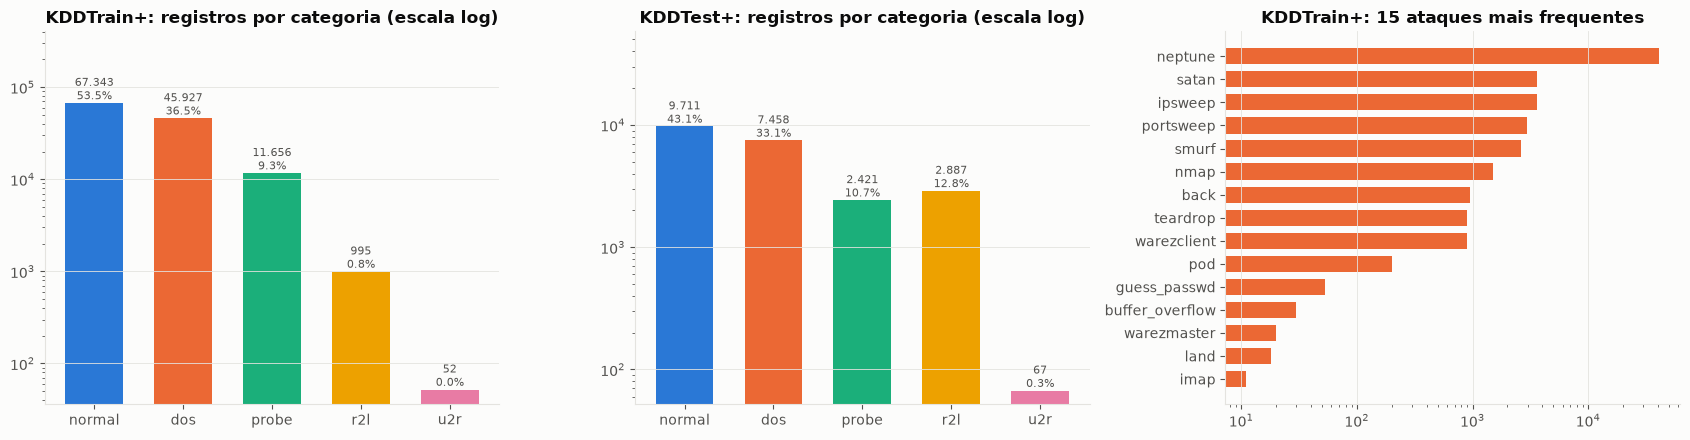

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (nome, df) in zip(axs[:2], [("KDDTrain+", treino_raw), ("KDDTest+", teste_raw)]):
    cont = df["grupo"].value_counts().reindex(ORDEM_GRUPOS).fillna(0)
    ax.bar(cont.index, cont.values, color=[PALETA[i] for i in range(5)], width=0.65)
    for i, v in enumerate(cont.values):
        ax.text(i, v, f"{int(v):,}\n{v / cont.sum():.1%}".replace(",", "."),
                ha="center", va="bottom", fontsize=8, color=TINTA_2)
    ax.set_yscale("log"); ax.set_ylim(top=cont.max() * 6)
    ax.set_title(f"{nome}: registros por categoria (escala log)")
    ax.grid(axis="x", visible=False)

top = treino_raw.loc[treino_raw["ataque"] == 1, "label"].value_counts().head(15)
axs[2].barh(top.index[::-1], top.values[::-1], color=COR_ATAQUE, height=0.7)
axs[2].set_xscale("log"); axs[2].set_title("KDDTrain+: 15 ataques mais frequentes")
axs[2].grid(axis="y", visible=False)
plt.tight_layout(); salvar(fig, "A1_distribuicao_classes")

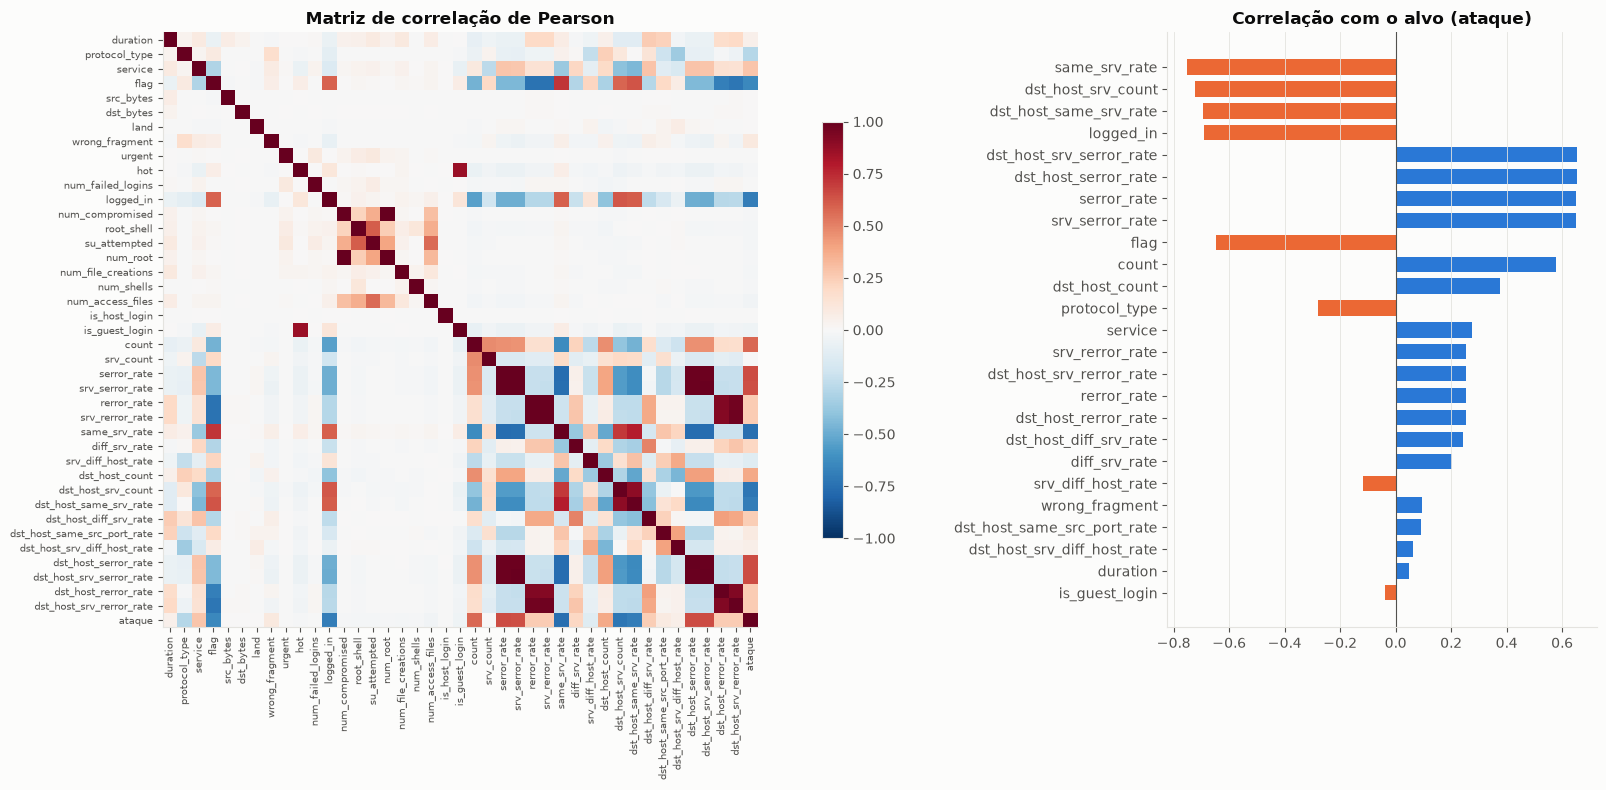

In [13]:
corr = pd.DataFrame(X_kdd, columns=FEAT_KDD).assign(ataque=y_kdd)
corr = corr.loc[:, corr.std() > 0].corr()
fig, axs = plt.subplots(1, 2, figsize=(19, 8), gridspec_kw={"width_ratios": [3, 1]})
im = axs[0].imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
axs[0].set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=7)
axs[0].set_yticks(range(len(corr)), corr.columns, fontsize=7)
axs[0].grid(False); axs[0].set_title("Matriz de correlação de Pearson")
fig.colorbar(im, ax=axs[0], shrink=0.7)
c_alvo = corr["ataque"].drop("ataque").sort_values()
barras_h(axs[1], c_alvo.index, c_alvo.values, "Correlação com o alvo (ataque)", n=25)
plt.tight_layout(); salvar(fig, "A1_correlacao")

## A.2 PCA

Ajustado nos 41 atributos padronizados do `KDDTrain+` inteiro. Gráficos:
variância explicada (por componente e acumulada), cargas (*loadings*) das
primeiras componentes, projeção 2D por classe binária e por categoria, biplot
e a projeção 3D com o giro de 360°.

componentes para 90%: 21 | 95%: 24 | 99%: 30  (de 41)


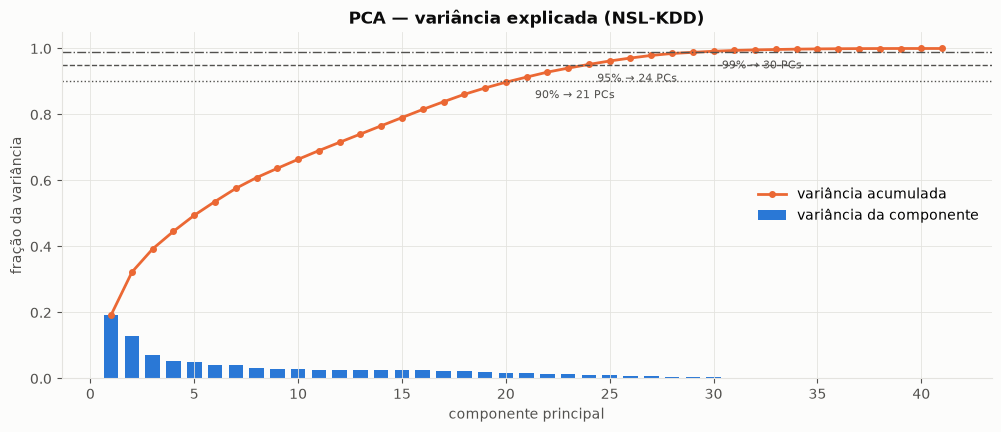

In [14]:
pca_kdd = PCA(random_state=SEED).fit(Xs_kdd)
var = pca_kdd.explained_variance_ratio_
acum = np.cumsum(var)
n90, n95, n99 = (np.searchsorted(acum, q) + 1 for q in (0.90, 0.95, 0.99))
print(f"componentes para 90%: {n90} | 95%: {n95} | 99%: {n99}  (de {len(var)})")

fig, ax = plt.subplots(figsize=(12, 4.5))
k = np.arange(1, len(var) + 1)
ax.bar(k, var, color=PALETA[0], width=0.7, label="variância da componente")
ax.plot(k, acum, color=PALETA[1], marker="o", markersize=4, label="variância acumulada")
for q, n, est in [(0.90, n90, ":"), (0.95, n95, "--"), (0.99, n99, "-.")]:
    ax.axhline(q, color=TINTA_2, linestyle=est, linewidth=1)
    ax.annotate(f"{q:.0%} → {n} PCs", (n, q), textcoords="offset points",
                xytext=(6, -12), fontsize=8, color=TINTA_2)
ax.set_xlabel("componente principal"); ax.set_ylabel("fração da variância")
ax.set_title("PCA — variância explicada (NSL-KDD)"); ax.legend(loc="center right")
salvar(fig, "A2_pca_variancia")

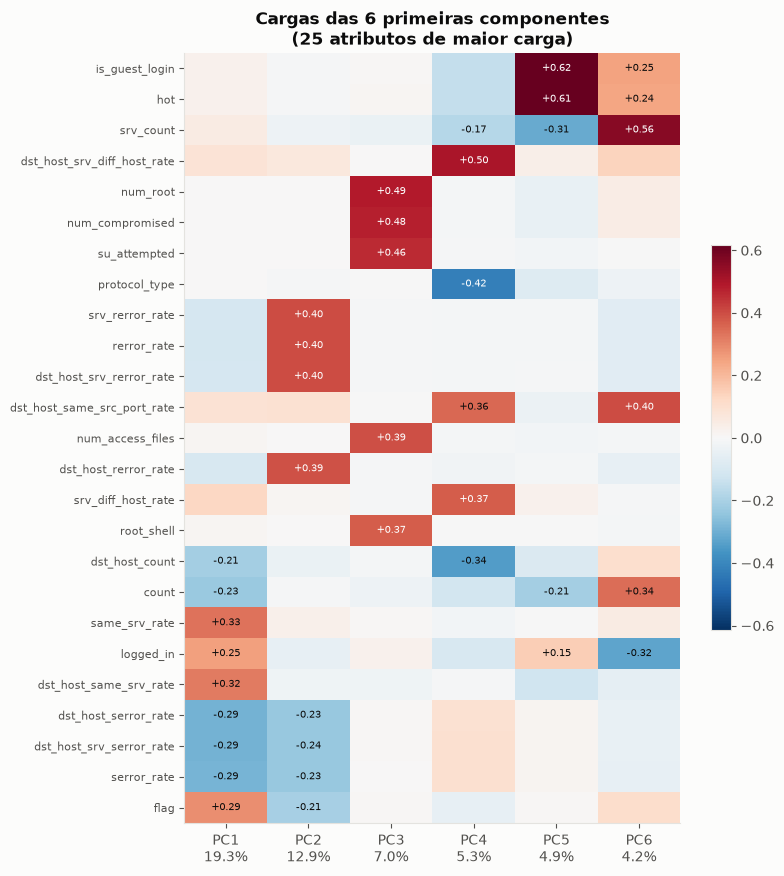

In [15]:
N_PC = 6
load = pd.DataFrame(pca_kdd.components_[:N_PC].T, index=FEAT_KDD,
                    columns=[f"PC{i+1}" for i in range(N_PC)])
ordem = load.abs().max(axis=1).sort_values(ascending=False).index[:25]
fig, ax = plt.subplots(figsize=(8, 10))
lim = np.abs(load.values).max()
im = ax.imshow(load.loc[ordem], cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(N_PC), [f"{c}\n{v:.1%}" for c, v in zip(load.columns, var)])
ax.set_yticks(range(len(ordem)), ordem, fontsize=8)
for i, f in enumerate(ordem):
    for j in range(N_PC):
        v = load.loc[f].iloc[j]
        if abs(v) >= 0.15:
            ax.text(j, i, f"{v:+.2f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(v) > lim * 0.6 else TINTA)
ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.5)
ax.set_title("Cargas das 6 primeiras componentes\n(25 atributos de maior carga)")
salvar(fig, "A2_pca_loadings")

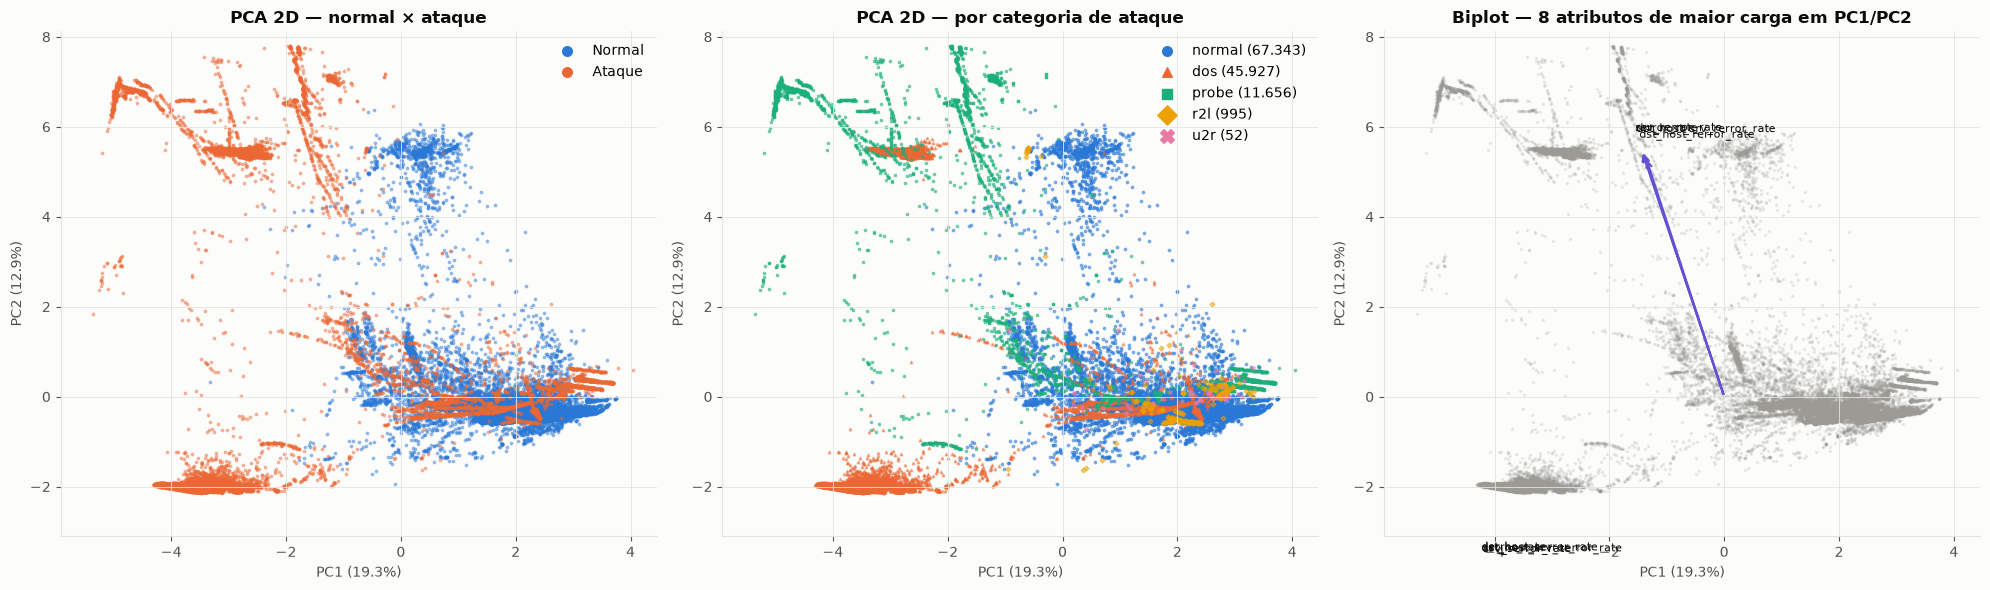

In [16]:
Z_kdd = pca_kdd.transform(Xs_kdd)[:, :3]
idx = amostra_estratificada(g_kdd, 40_000)
fig, axs = plt.subplots(1, 3, figsize=(20, 6))

for valor, nome, cor in [(0, "Normal", COR_NORMAL), (1, "Ataque", COR_ATAQUE)]:
    m = y_kdd[idx] == valor
    axs[0].scatter(Z_kdd[idx][m, 0], Z_kdd[idx][m, 1], s=3, alpha=0.4, color=cor, label=nome)
axs[0].set_title("PCA 2D — normal × ataque")

for i, gname in enumerate(ORDEM_GRUPOS):
    m = g_kdd[idx] == gname
    axs[1].scatter(Z_kdd[idx][m, 0], Z_kdd[idx][m, 1], s=6 if i > 2 else 3,
                   alpha=0.5, color=PALETA[i], marker=MARCADORES[i],
                   label=f"{gname} ({(g_kdd == gname).sum():,})".replace(",", "."))
axs[1].set_title("PCA 2D — por categoria de ataque")

# biplot: setas das 8 maiores cargas no plano PC1×PC2
axs[2].scatter(Z_kdd[idx, 0], Z_kdd[idx, 1], s=2, alpha=0.15, color="#9b9a95")
vet = pca_kdd.components_[:2].T
top = np.argsort(np.linalg.norm(vet, axis=1))[::-1][:8]
esc = np.percentile(np.abs(Z_kdd[idx, :2]), 97) / np.abs(vet[top]).max()
for t in top:
    axs[2].annotate("", xy=vet[t] * esc, xytext=(0, 0),
                    arrowprops=dict(arrowstyle="->", color=PALETA[6], lw=1.5))
    axs[2].text(*(vet[t] * esc * 1.08), FEAT_KDD[t], fontsize=8, color=TINTA)
axs[2].set_title("Biplot — 8 atributos de maior carga em PC1/PC2")

for ax in axs:
    ax.set_xlabel(f"PC1 ({var[0]:.1%})"); ax.set_ylabel(f"PC2 ({var[1]:.1%})")
    lo, hi = np.percentile(Z_kdd[idx, :2], [0.5, 99.5], axis=0)
    ax.set_xlim(lo[0] - 1, hi[0] + 1); ax.set_ylim(lo[1] - 1, hi[1] + 1)
for ax in axs[:2]:
    leg = ax.legend(markerscale=4)
    for h in leg.legend_handles: h.set_alpha(1)
plt.tight_layout(); salvar(fig, "A2_pca_2d")

### PCA 3D — giro de 360° (passo de 2,5°)

Dois giros: binário (normal × ataque) e por categoria. Os quadros e o GIF ficam
em `notebooks/figuras/pca360_kdd_binario/` e `.../pca360_kdd_categorias/`.

[+] 144 quadros (2.5° cada) em /home/adelgrin/git/TCC/notebooks/figuras/pca360_kdd_binario [21s, 30.000 pontos]
[+] GIF: /home/adelgrin/git/TCC/notebooks/figuras/pca360_kdd_binario/giro_360.gif (8.1 MB)


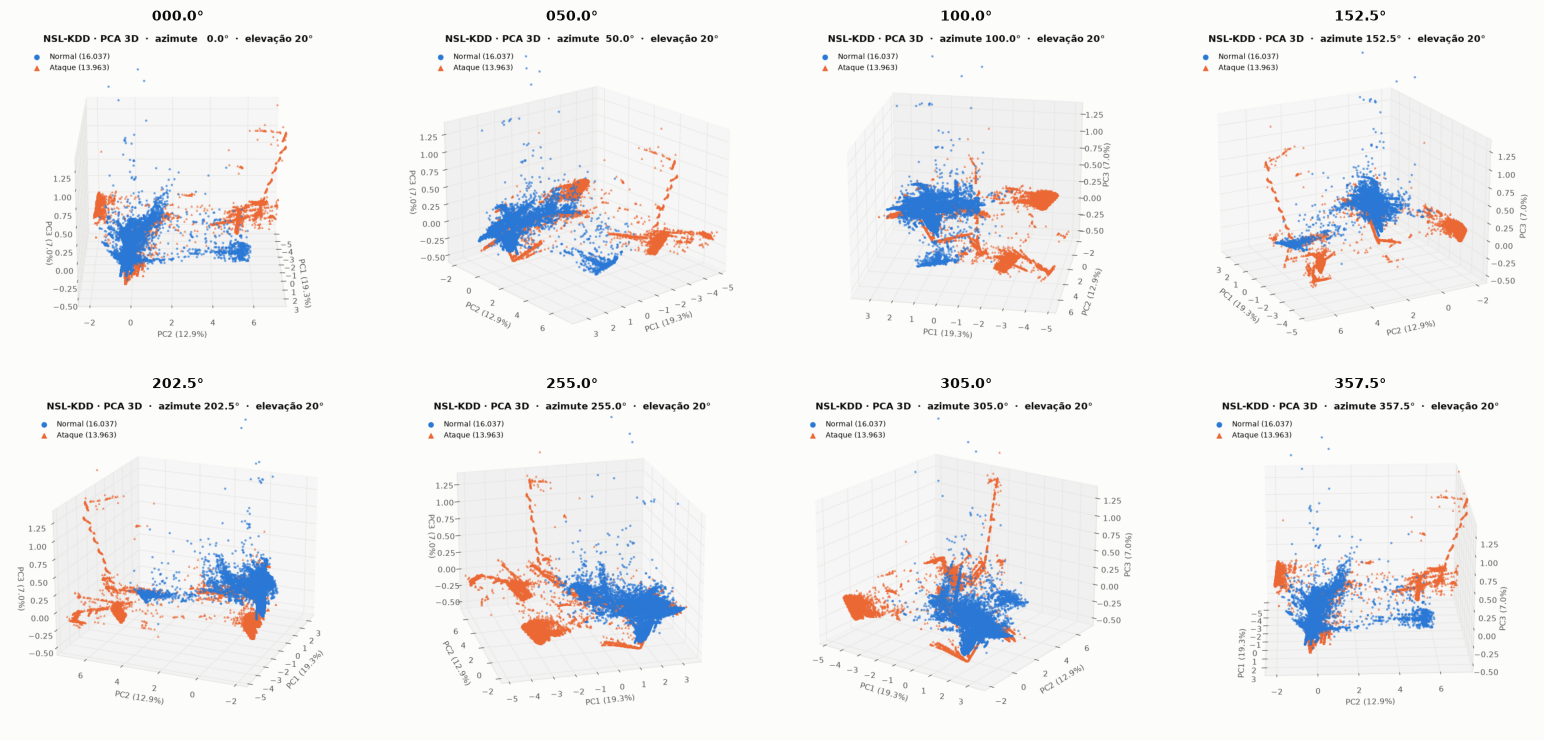

In [17]:
quadros_bin = pca_360(
    Z_kdd, y_kdd, [(0, "Normal"), (1, "Ataque")],
    FIG / "pca360_kdd_binario", titulo="NSL-KDD · PCA 3D",
    passo=2.5, elev=20, n_max=30_000, var_exp=var)
mostrar_quadros(quadros_bin)

[+] 144 quadros (2.5° cada) em /home/adelgrin/git/TCC/notebooks/figuras/pca360_kdd_categorias [23s, 30.102 pontos]
[+] GIF: /home/adelgrin/git/TCC/notebooks/figuras/pca360_kdd_categorias/giro_360.gif (6.8 MB)


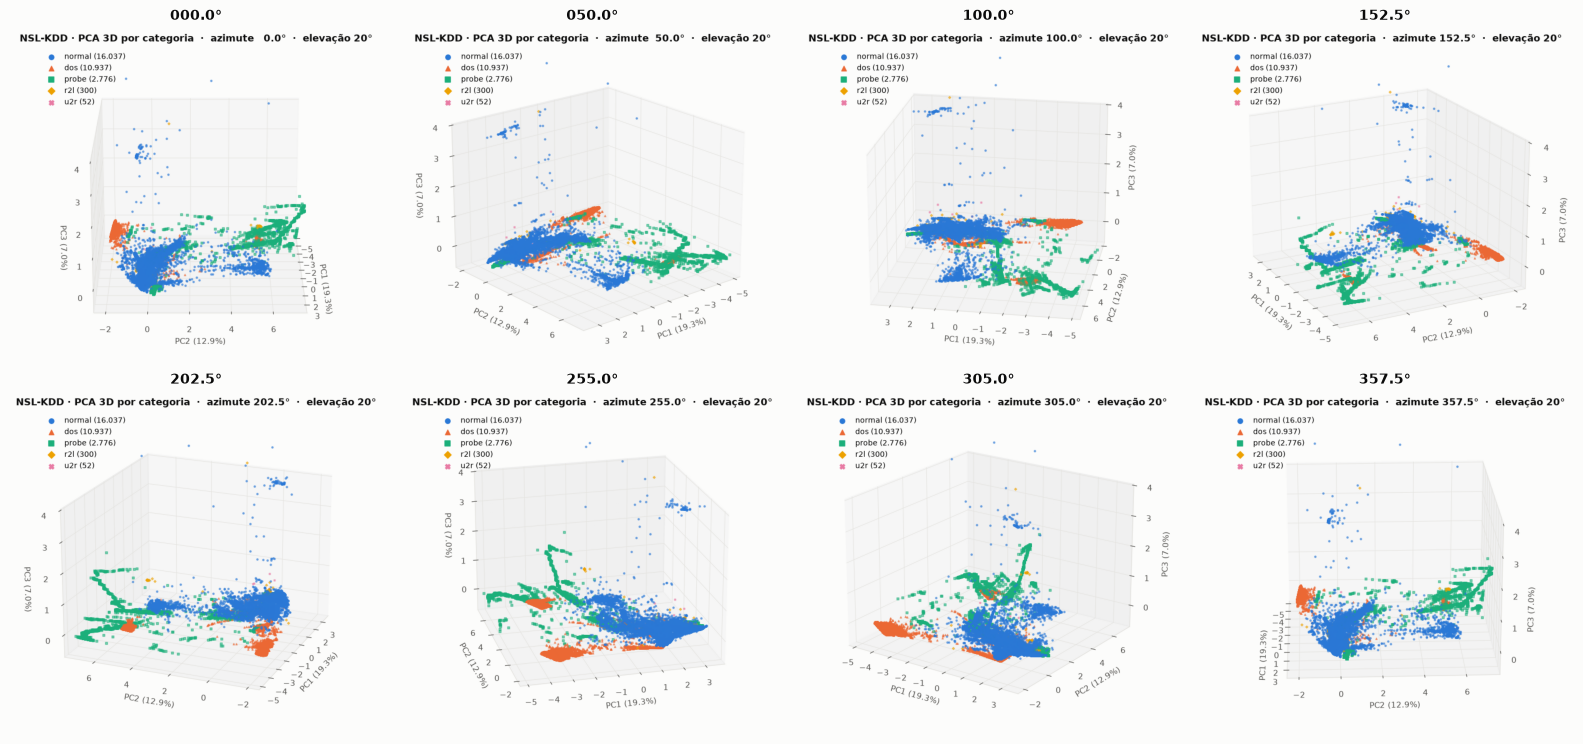

In [18]:
quadros_cat = pca_360(
    Z_kdd, g_kdd, [(g, g) for g in ORDEM_GRUPOS],
    FIG / "pca360_kdd_categorias", titulo="NSL-KDD · PCA 3D por categoria",
    passo=2.5, elev=20, n_max=30_000, var_exp=var)
mostrar_quadros(quadros_cat)

## A.3 Treino dos cinco classificadores

Mesmos hiperparâmetros do texto. O SVM com `kernel="linear"` (SVC) é o mais
lento — da ordem de minutos nesta base, como na tabela do texto.

In [19]:
MODELOS = {
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1),
    "Decision Tree": DecisionTreeClassifier(random_state=SEED),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
    "SVM (linear)": SVC(kernel="linear", random_state=SEED),
}
COR_MODELO = {nome: PALETA[i] for i, nome in enumerate(MODELOS)}

res = {}
for nome, modelo in MODELOS.items():
    t0 = time.perf_counter(); modelo.fit(Xtr, ytr); t_tr = time.perf_counter() - t0
    r = {"modelo": modelo}
    for conj, X_, y_ in [("retido", Xho, yho), ("teste", Xs_kdd_teste, y_kdd_teste)]:
        t0 = time.perf_counter(); pred = modelo.predict(X_); t_te = time.perf_counter() - t0
        s = escore_de(modelo, X_)
        r[conj] = {"pred": pred, "escore": s,
                   "m": metricas(y_, pred, s, t_tr, t_te)}
    res[nome] = r
    m1, m2 = r["retido"]["m"], r["teste"]["m"]
    print(f"{nome:<20} treino {t_tr:7.2f}s | retido F1={m1['f1']:.4f} "
          f"| KDDTest+ F1={m2['f1']:.4f} recall={m2['recall']:.4f}")

Random Forest        treino    1.66s | retido F1=0.9989 | KDDTest+ F1=0.7466 recall=0.6081
Decision Tree        treino    0.52s | retido F1=0.9979 | KDDTest+ F1=0.8346 recall=0.7320
KNN (k=5)            treino    0.00s | retido F1=0.9955 | KDDTest+ F1=0.7508 recall=0.6122
Logistic Regression  treino    2.35s | retido F1=0.9497 | KDDTest+ F1=0.7380 recall=0.6140
SVM (linear)         treino  147.94s | retido F1=0.9561 | KDDTest+ F1=0.7356 recall=0.5945


## A.4 Tabelas de métricas

`retido` = 30% do `KDDTrain+` (comparável à tabela do texto).
`teste` = `KDDTest+` (com ataques novos).

In [20]:
tab_ho = tabela_metricas([{"modelo": n, **r["retido"]["m"]} for n, r in res.items()])
tab_te = tabela_metricas([{"modelo": n, **r["teste"]["m"]} for n, r in res.items()])
print("Partição retida (30% do KDDTrain+)"); display(tab_ho)
print("KDDTest+"); display(tab_te)
tab_ho.to_csv(FIG / "A4_metricas_retido.csv"); tab_te.to_csv(FIG / "A4_metricas_kddtest.csv")

Partição retida (30% do KDDTrain+)


,acuracia,precisao,recall,f1,especificidade,fpr,acuracia_bal,mcc,roc_auc,ap,t_treino_s,t_teste_s,tp,fp,fn,tn
modelo,,,,,,,,,,,,,,,,
Random Forest,0.9990,0.9995,0.9984,0.9989,0.9996,0.0004,0.9990,0.9980,1.0000,1.0000,1.6587,0.0463,17561,9,28,20194
Decision Tree,0.9981,0.9981,0.9977,0.9979,0.9984,0.0016,0.9980,0.9961,0.9980,0.9969,0.5213,0.0034,17549,33,40,20170
KNN (k=5),0.9958,0.9955,0.9956,0.9955,0.9961,0.0039,0.9958,0.9917,0.9993,0.9990,0.0045,2.5125,17511,79,78,20124
Logistic Regression,0.9537,0.9597,0.9399,0.9497,0.9656,0.0344,0.9528,0.9069,0.9918,0.9903,2.3468,0.0056,16532,694,1057,19509
SVM (linear),0.9596,0.9662,0.9462,0.9561,0.9712,0.0288,0.9587,0.9188,0.9892,0.9885,147.9429,7.4918,16643,582,946,19621


KDDTest+


,acuracia,precisao,recall,f1,especificidade,fpr,acuracia_bal,mcc,roc_auc,ap,t_treino_s,t_teste_s,tp,fp,fn,tn
modelo,,,,,,,,,,,,,,,,
Random Forest,0.7650,0.9668,0.6081,0.7466,0.9724,0.0276,0.7903,0.5996,0.9632,0.9635,1.6587,0.0354,7804,268,5029,9443
Decision Tree,0.8348,0.9706,0.7320,0.8346,0.9707,0.0293,0.8513,0.7030,0.8515,0.8631,0.5213,0.0021,9394,285,3439,9426
KNN (k=5),0.7686,0.9704,0.6122,0.7508,0.9753,0.0247,0.7938,0.6064,0.8221,0.8402,0.0045,1.4674,7857,240,4976,9471
Logistic Regression,0.7519,0.9250,0.6140,0.7380,0.9342,0.0658,0.7741,0.5598,0.8709,0.9026,2.3468,0.0026,7879,639,4954,9072
SVM (linear),0.7568,0.9647,0.5945,0.7356,0.9713,0.0287,0.7829,0.5871,0.8514,0.8963,147.9429,4.4752,7629,279,5204,9432


In [21]:
for nome, r in res.items():
    print(f"\n=== {nome} — KDDTest+ ===")
    print(classification_report(y_kdd_teste, r["teste"]["pred"],
                                target_names=["Normal", "Ataque"], digits=4))


=== Random Forest — KDDTest+ ===
              precision    recall  f1-score   support

      Normal     0.6525    0.9724    0.7810      9711
      Ataque     0.9668    0.6081    0.7466     12833

    accuracy                         0.7650     22544
   macro avg     0.8097    0.7903    0.7638     22544
weighted avg     0.8314    0.7650    0.7614     22544


=== Decision Tree — KDDTest+ ===
              precision    recall  f1-score   support

      Normal     0.7327    0.9707    0.8350      9711
      Ataque     0.9706    0.7320    0.8346     12833

    accuracy                         0.8348     22544
   macro avg     0.8516    0.8513    0.8348     22544
weighted avg     0.8681    0.8348    0.8348     22544


=== KNN (k=5) — KDDTest+ ===
              precision    recall  f1-score   support

      Normal     0.6556    0.9753    0.7841      9711
      Ataque     0.9704    0.6122    0.7508     12833

    accuracy                         0.7686     22544
   macro avg     0.8130    0.7

## A.5 Gráficos por modelo

Para cada modelo, uma figura com: matriz de confusão (absoluta e normalizada)
nos dois conjuntos, ROC, PR, distribuição do escore por classe e taxa de
detecção por categoria de ataque no `KDDTest+`.

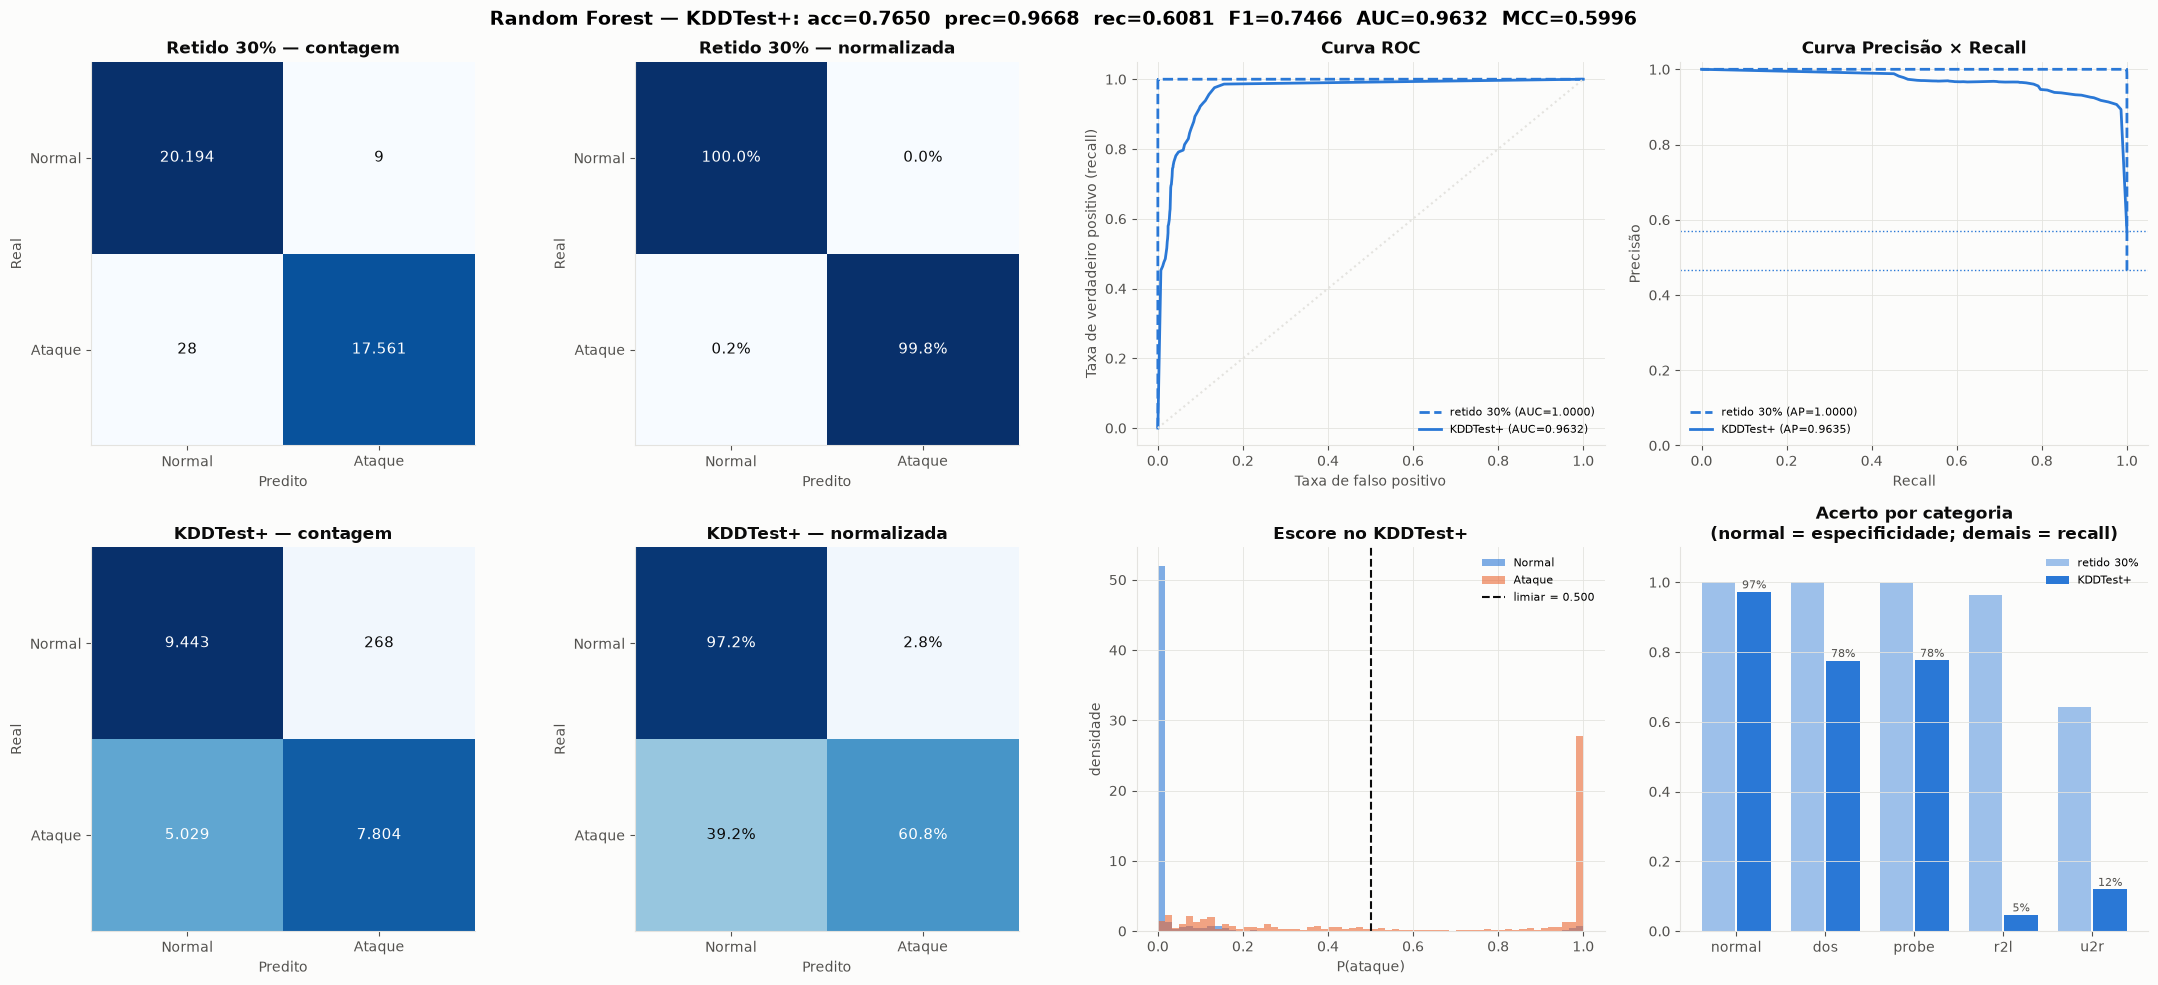

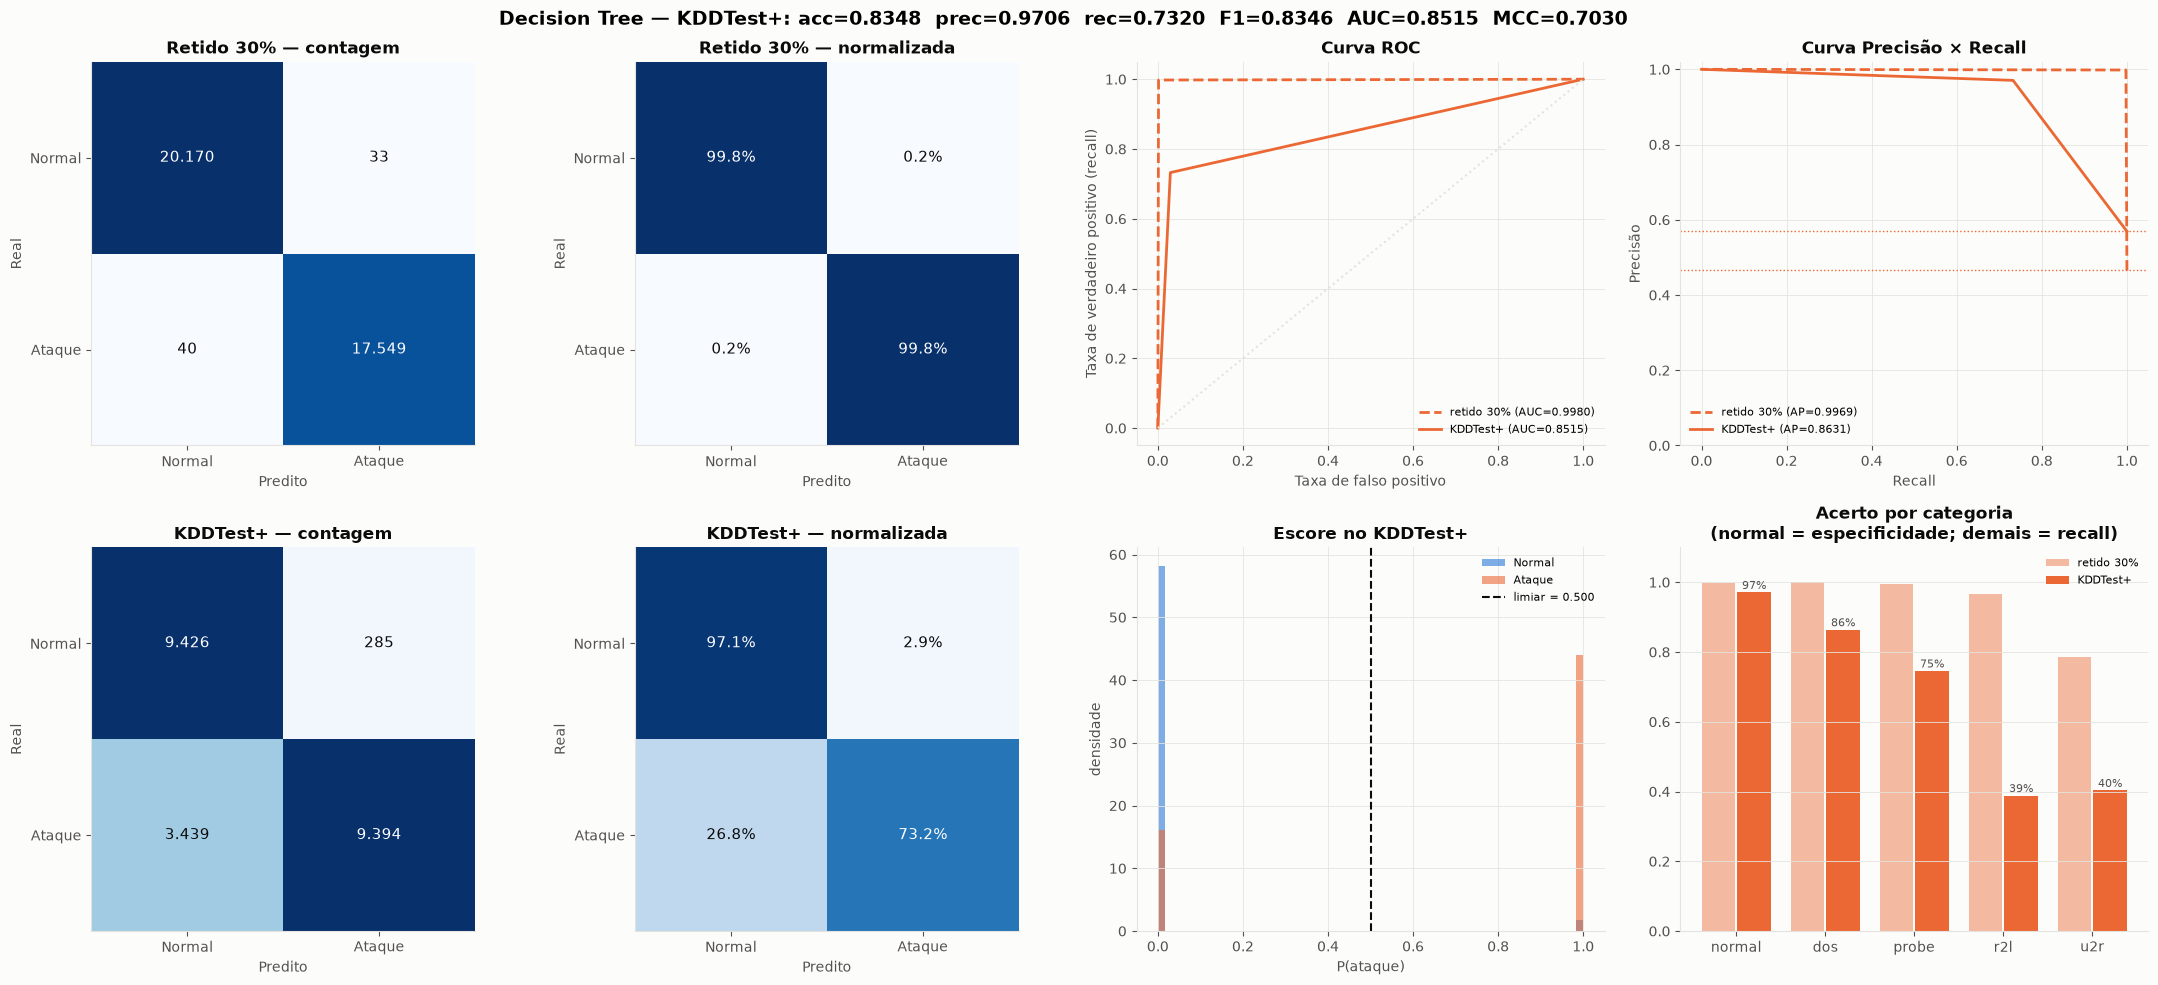

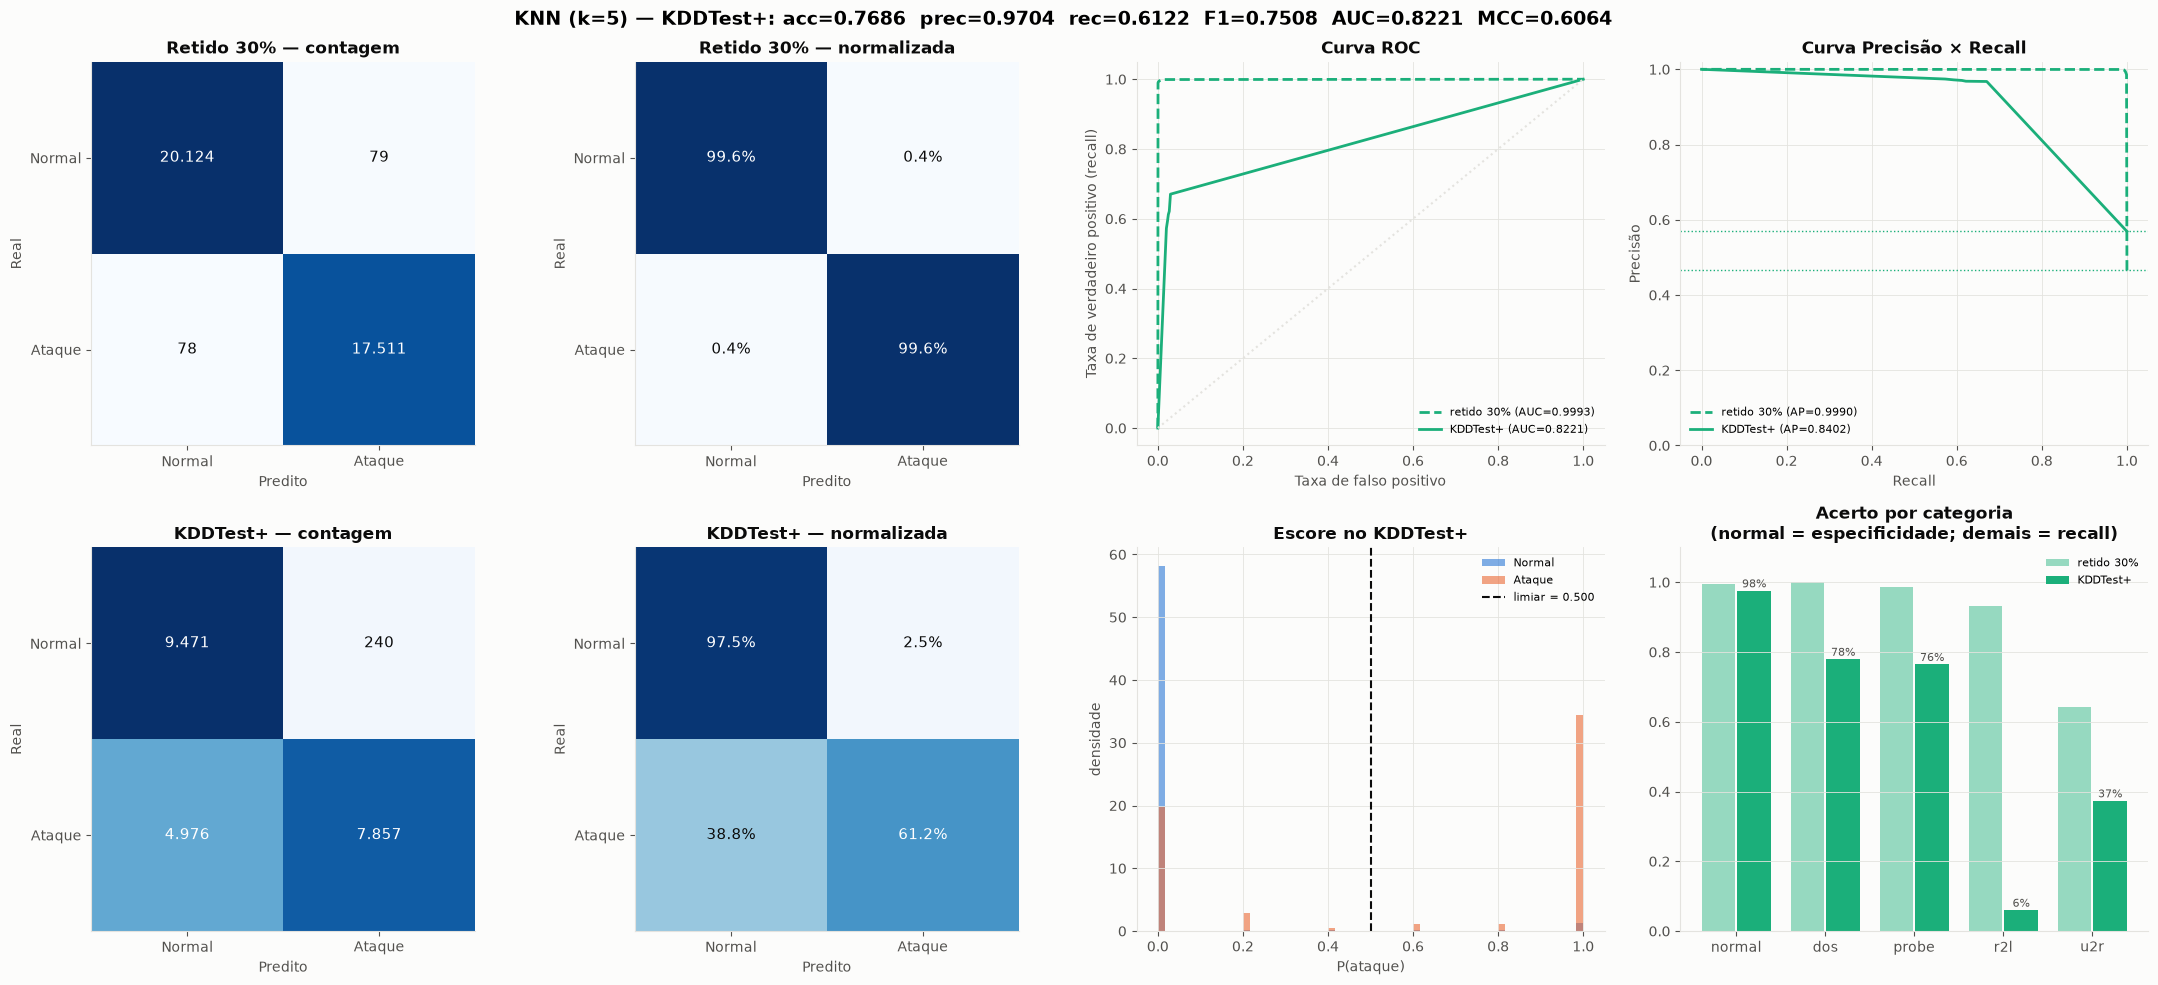

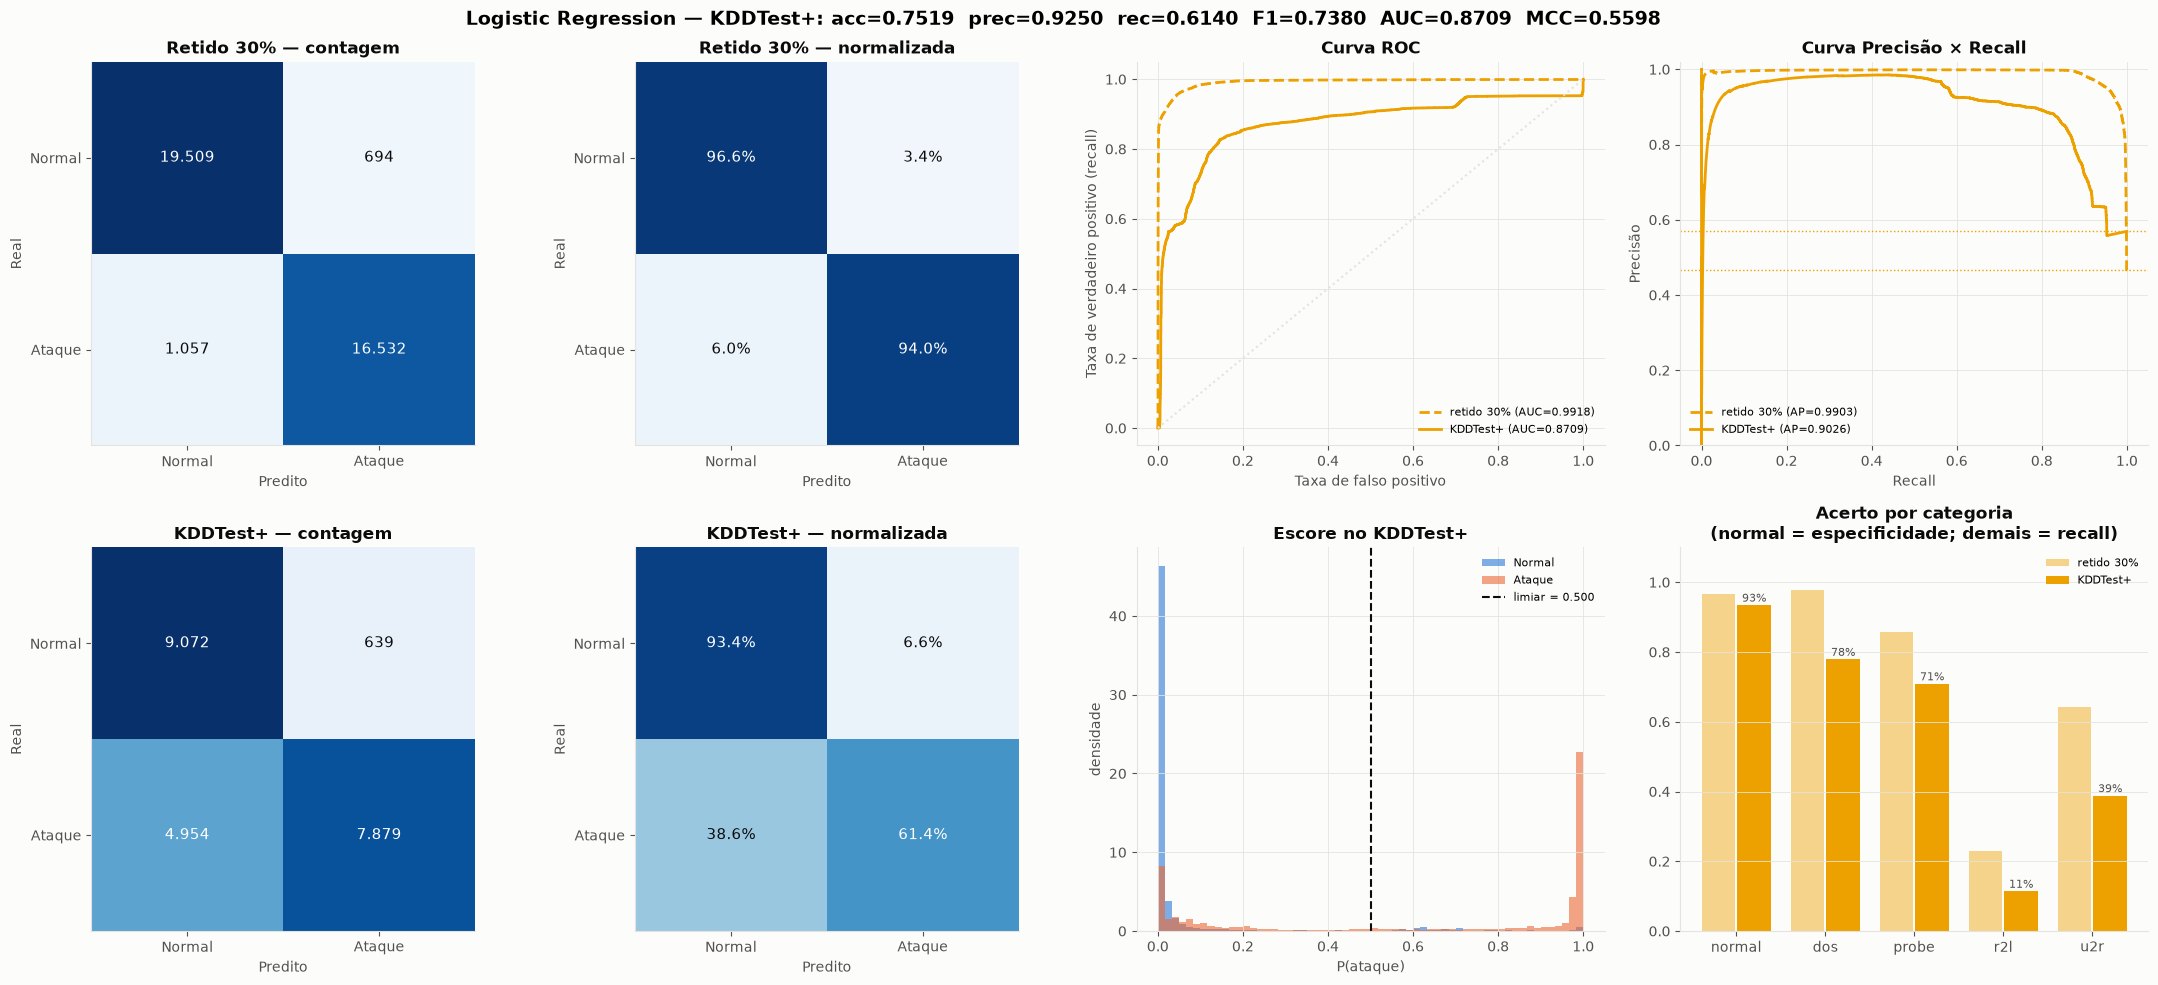

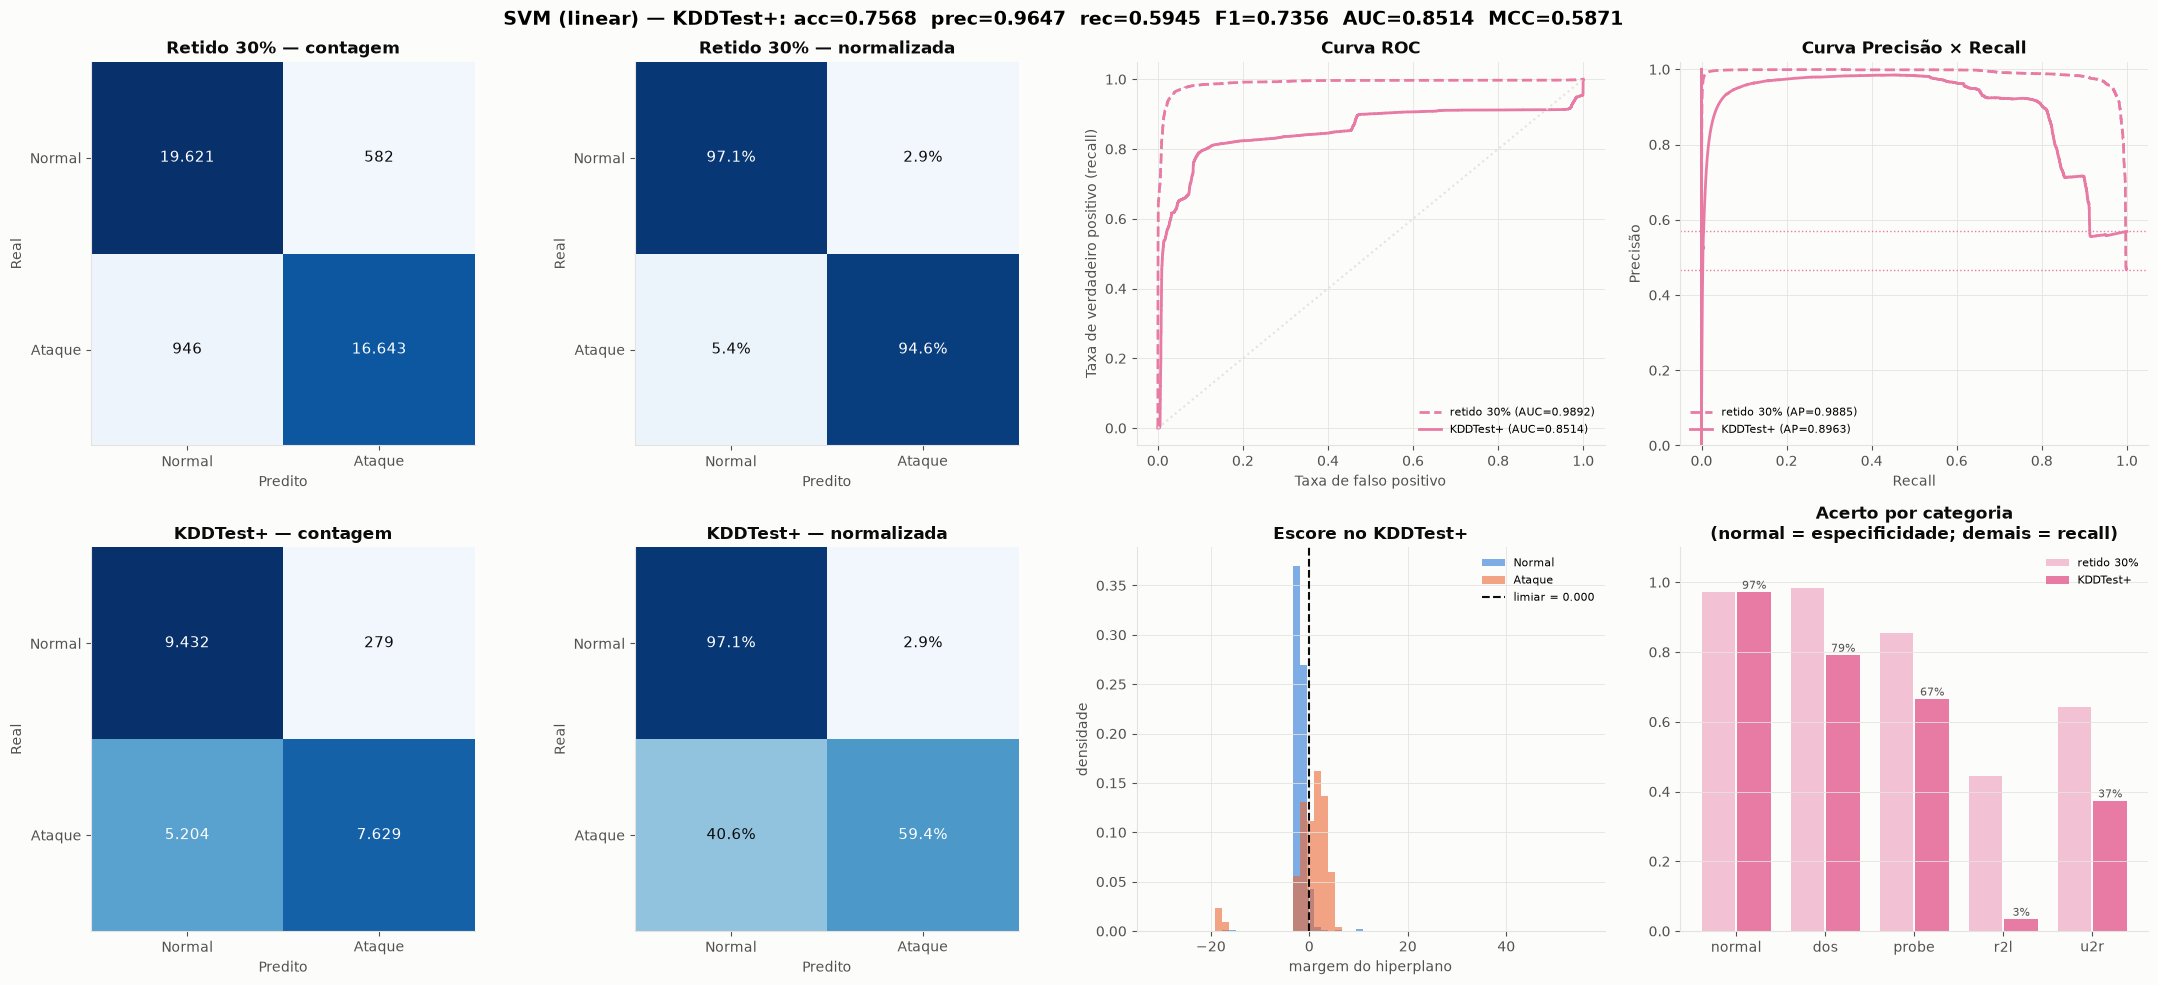

In [22]:
def recall_por_grupo(grupos, y, pred):
    out = {}
    for gname in ORDEM_GRUPOS:
        m = grupos == gname
        if m.any():
            # para 'normal' a taxa e de acerto (especificidade); para ataques, recall
            out[gname] = (pred[m] == y[m]).mean()
    return pd.Series(out)


def painel_modelo(nome, r):
    cor = COR_MODELO[nome]
    fig, axs = plt.subplots(2, 4, figsize=(22, 10))
    matriz_confusao(axs[0, 0], yho, r["retido"]["pred"], "Retido 30% — contagem")
    matriz_confusao(axs[0, 1], yho, r["retido"]["pred"], "Retido 30% — normalizada", True)
    matriz_confusao(axs[1, 0], y_kdd_teste, r["teste"]["pred"], "KDDTest+ — contagem")
    matriz_confusao(axs[1, 1], y_kdd_teste, r["teste"]["pred"], "KDDTest+ — normalizada", True)
    curvas = [("retido 30%", yho, r["retido"]["escore"], cor, "--"),
              ("KDDTest+", y_kdd_teste, r["teste"]["escore"], cor, "-")]
    curva_roc(axs[0, 2], curvas)
    curva_pr(axs[0, 3], curvas)
    nome_s = "P(ataque)" if hasattr(r["modelo"], "predict_proba") else "margem do hiperplano"
    lim = 0.5 if hasattr(r["modelo"], "predict_proba") else 0.0
    hist_escore(axs[1, 2], y_kdd_teste, r["teste"]["escore"],
                "Escore no KDDTest+", lim, nome_s)
    rg = recall_por_grupo(g_kdd_teste, y_kdd_teste, r["teste"]["pred"])
    rh = recall_por_grupo(gho, yho, r["retido"]["pred"])
    x = np.arange(len(rg))
    axs[1, 3].bar(x - 0.2, rh.reindex(rg.index), 0.38, color=cor, alpha=0.45, label="retido 30%")
    axs[1, 3].bar(x + 0.2, rg, 0.38, color=cor, label="KDDTest+")
    for xi, v in zip(x, rg):
        axs[1, 3].text(xi + 0.2, v + 0.01, f"{v:.0%}", ha="center", fontsize=8, color=TINTA_2)
    axs[1, 3].set_xticks(x, rg.index); axs[1, 3].set_ylim(0, 1.1)
    axs[1, 3].set_title("Acerto por categoria\n(normal = especificidade; demais = recall)")
    axs[1, 3].legend(fontsize=8); axs[1, 3].grid(axis="x", visible=False)
    m = r["teste"]["m"]
    fig.suptitle(f"{nome} — KDDTest+: acc={m['acuracia']:.4f}  prec={m['precisao']:.4f}  "
                 f"rec={m['recall']:.4f}  F1={m['f1']:.4f}  AUC={m['roc_auc']:.4f}  "
                 f"MCC={m['mcc']:.4f}", fontsize=14, fontweight="bold")
    plt.tight_layout()
    salvar(fig, "A5_" + nome.split(" (")[0].lower().replace(" ", "_"))


for nome, r in res.items():
    painel_modelo(nome, r)

## A.6 Gráficos específicos de cada modelo

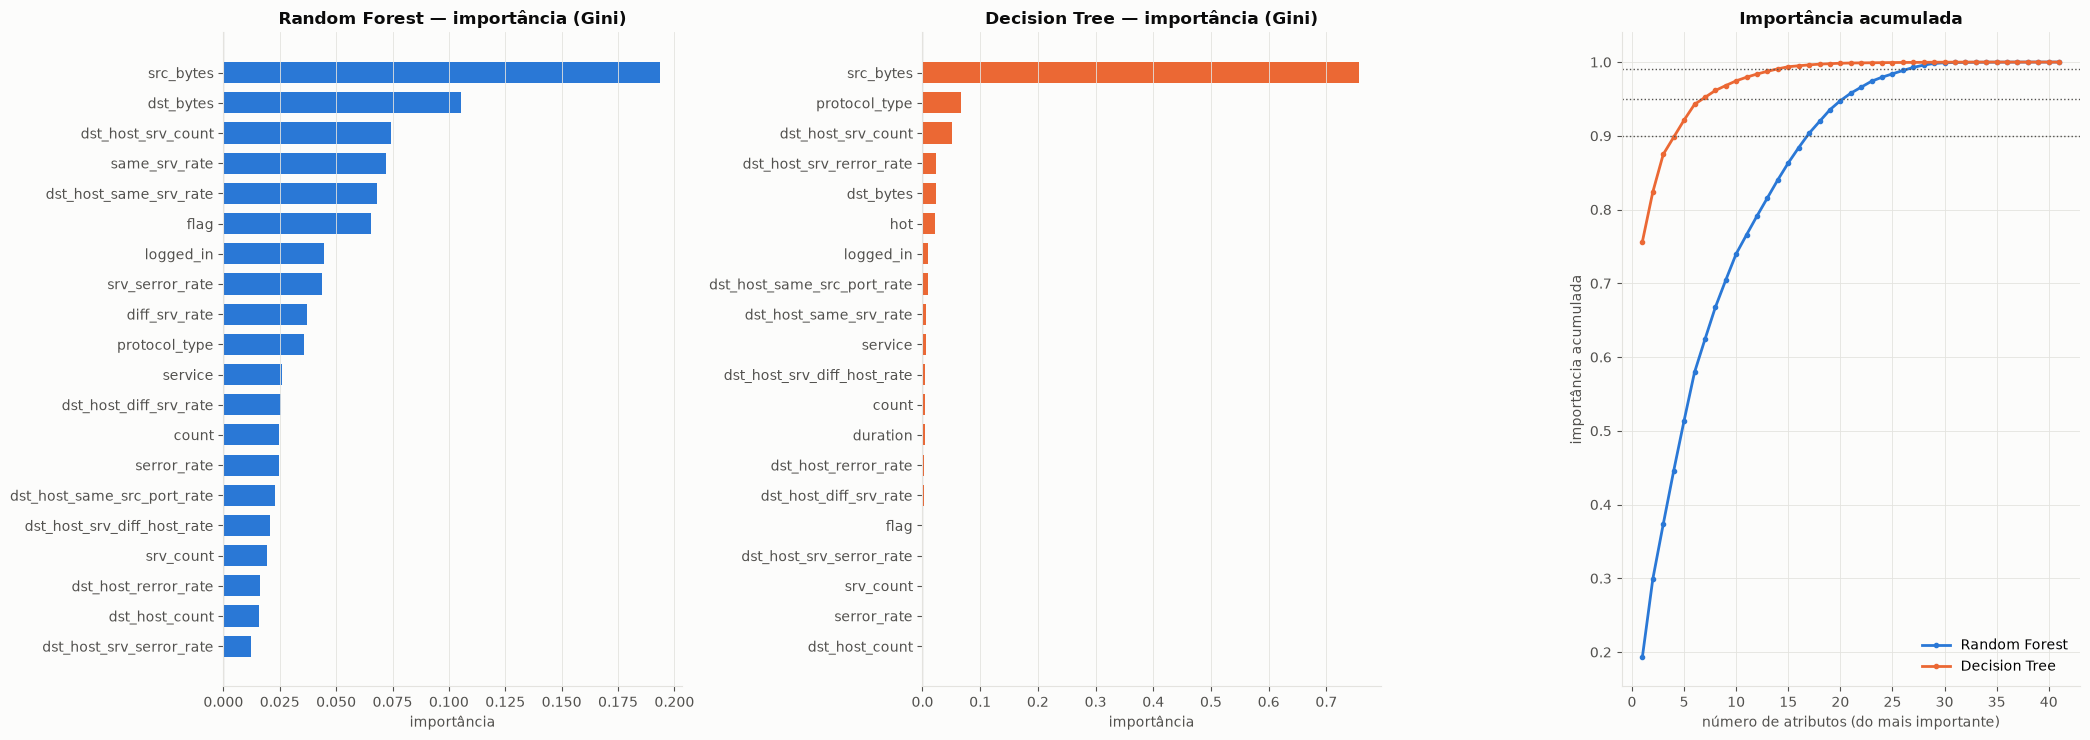

In [23]:
rf, dt = MODELOS["Random Forest"], MODELOS["Decision Tree"]
fig, axs = plt.subplots(1, 3, figsize=(21, 7.5))
barras_h(axs[0], FEAT_KDD, rf.feature_importances_, "Random Forest — importância (Gini)",
         COR_MODELO["Random Forest"], "importância", n=20)
barras_h(axs[1], FEAT_KDD, dt.feature_importances_, "Decision Tree — importância (Gini)",
         COR_MODELO["Decision Tree"], "importância", n=20)
for nome, mod in [("Random Forest", rf), ("Decision Tree", dt)]:
    acum_imp = np.cumsum(np.sort(mod.feature_importances_)[::-1])
    axs[2].plot(np.arange(1, len(acum_imp) + 1), acum_imp, color=COR_MODELO[nome],
                marker="o", markersize=3, label=nome)
for q in (0.90, 0.95, 0.99):
    axs[2].axhline(q, color=TINTA_2, linestyle=":", linewidth=1)
axs[2].set_xlabel("número de atributos (do mais importante)")
axs[2].set_ylabel("importância acumulada"); axs[2].legend()
axs[2].set_title("Importância acumulada")
plt.tight_layout(); salvar(fig, "A6_importancias")

Decision Tree: profundidade 22, 247 folhas


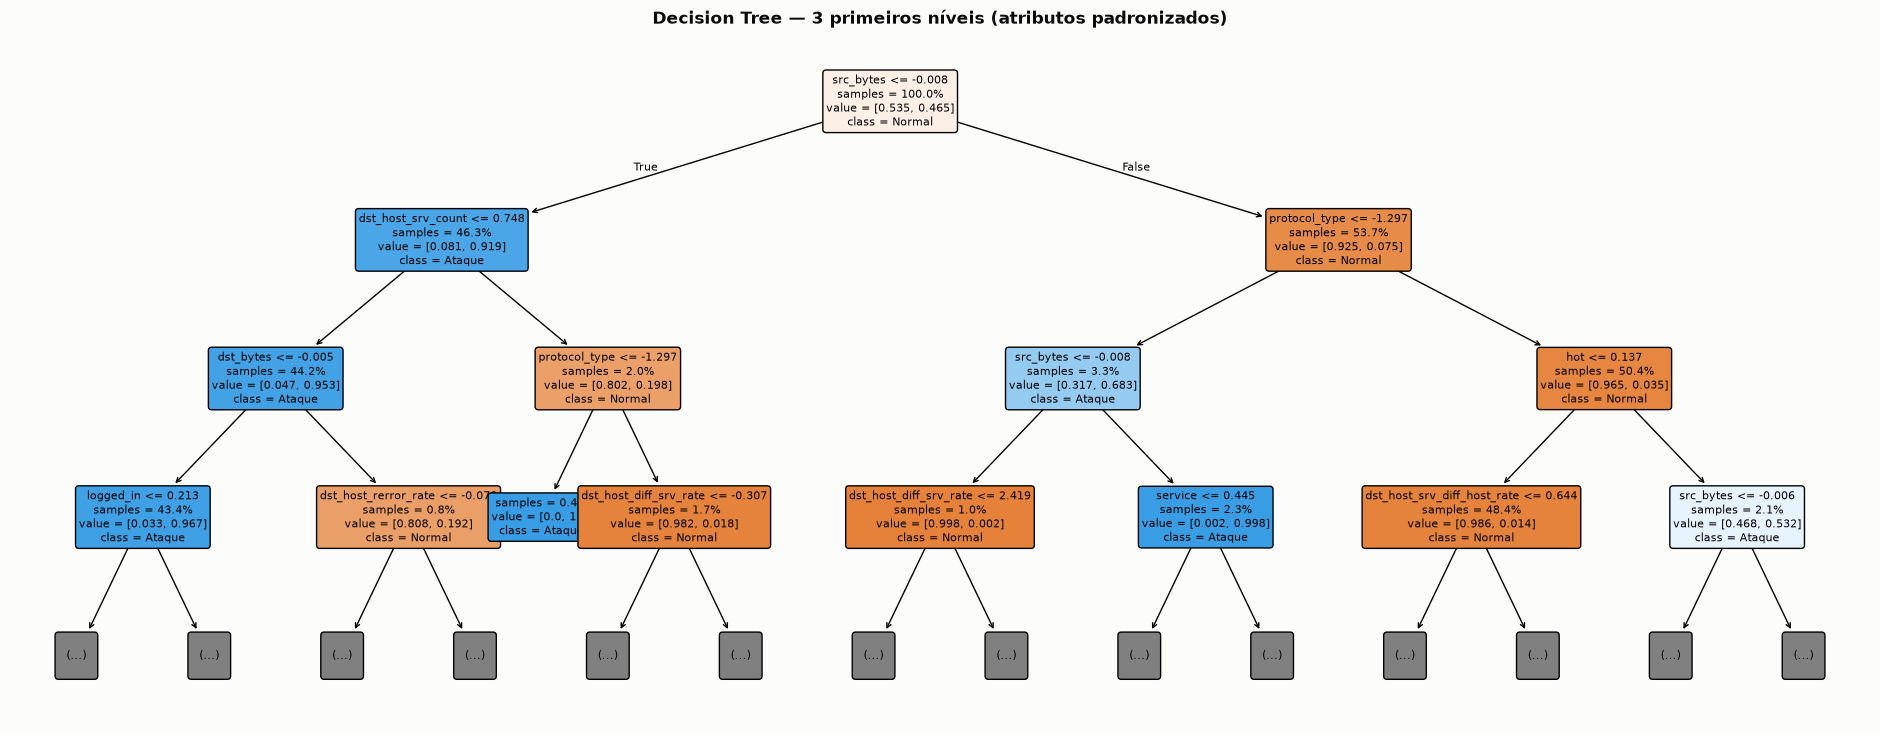

In [24]:
# os 3 primeiros niveis da arvore (a arvore inteira tem milhares de nos)
print(f"Decision Tree: profundidade {dt.get_depth()}, {dt.get_n_leaves()} folhas")
fig, ax = plt.subplots(figsize=(24, 9))
plot_tree(dt, max_depth=3, feature_names=FEAT_KDD, class_names=["Normal", "Ataque"],
          filled=True, impurity=False, proportion=True, rounded=True, fontsize=8, ax=ax)
ax.set_title("Decision Tree — 3 primeiros níveis (atributos padronizados)")
salvar(fig, "A6_arvore")

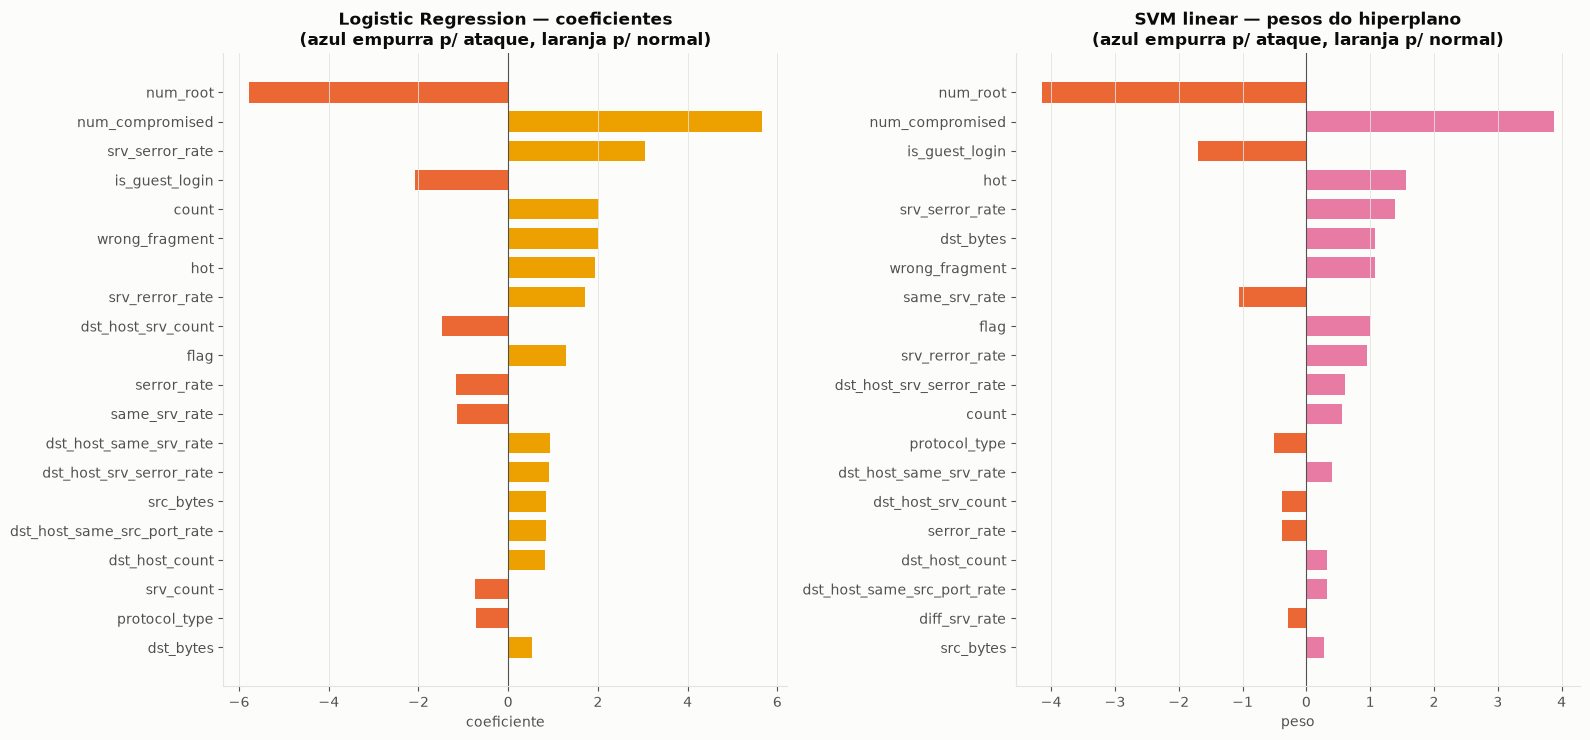

SVM: 9.231 vetores de suporte (normal: 4.620, ataque: 4.611)


In [25]:
fig, axs = plt.subplots(1, 2, figsize=(16, 7.5))
barras_h(axs[0], FEAT_KDD, MODELOS["Logistic Regression"].coef_[0],
         "Logistic Regression — coeficientes\n(azul empurra p/ ataque, laranja p/ normal)",
         COR_MODELO["Logistic Regression"], "coeficiente", n=20)
barras_h(axs[1], FEAT_KDD, MODELOS["SVM (linear)"].coef_[0],
         "SVM linear — pesos do hiperplano\n(azul empurra p/ ataque, laranja p/ normal)",
         COR_MODELO["SVM (linear)"], "peso", n=20)
plt.tight_layout(); salvar(fig, "A6_coeficientes_lineares")
ns = MODELOS["SVM (linear)"].n_support_
print(f"SVM: {n_br(ns.sum())} vetores de suporte (normal: {n_br(ns[0])}, ataque: {n_br(ns[1])})")

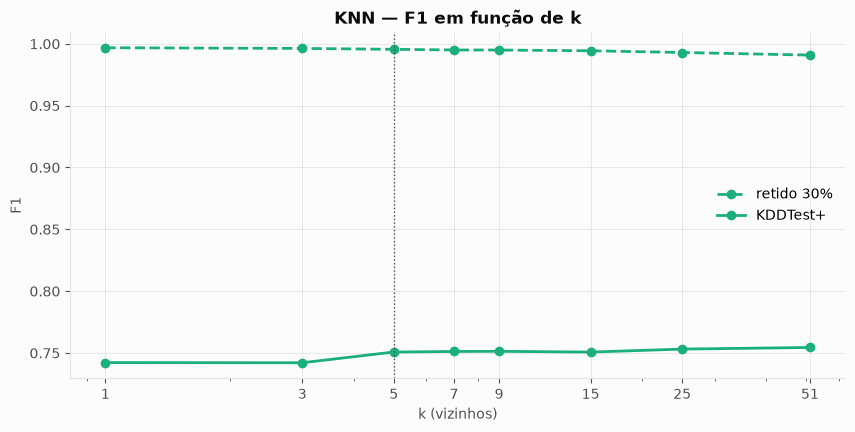

In [26]:
# KNN: F1 em funcao de k (retido e KDDTest+)
ks = [1, 3, 5, 7, 9, 15, 25, 51]
f1k = {"retido 30%": [], "KDDTest+": []}
for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k, n_jobs=-1).fit(Xtr, ytr)
    f1k["retido 30%"].append(f1_score(yho, knn.predict(Xho)))
    f1k["KDDTest+"].append(f1_score(y_kdd_teste, knn.predict(Xs_kdd_teste)))
fig, ax = plt.subplots(figsize=(10, 4.5))
for (rot, v), est in zip(f1k.items(), ["--", "-"]):
    ax.plot(ks, v, color=COR_MODELO["KNN (k=5)"], linestyle=est, marker="o", label=rot)
ax.axvline(5, color=TINTA_2, linestyle=":", linewidth=1)
ax.set_xscale("log"); ax.set_xticks(ks, ks)
ax.set_xlabel("k (vizinhos)"); ax.set_ylabel("F1"); ax.legend()
ax.set_title("KNN — F1 em função de k")
salvar(fig, "A6_knn_k")

### Fronteiras de decisão no plano PCA (PC1 × PC2)

Cada modelo é retreinado **só com PC1 e PC2** (amostra de 20 mil pontos) para
desenhar a fronteira. É uma ilustração de como cada família de modelo recorta
o espaço — não é o modelo avaliado acima, que usa os 41 atributos.

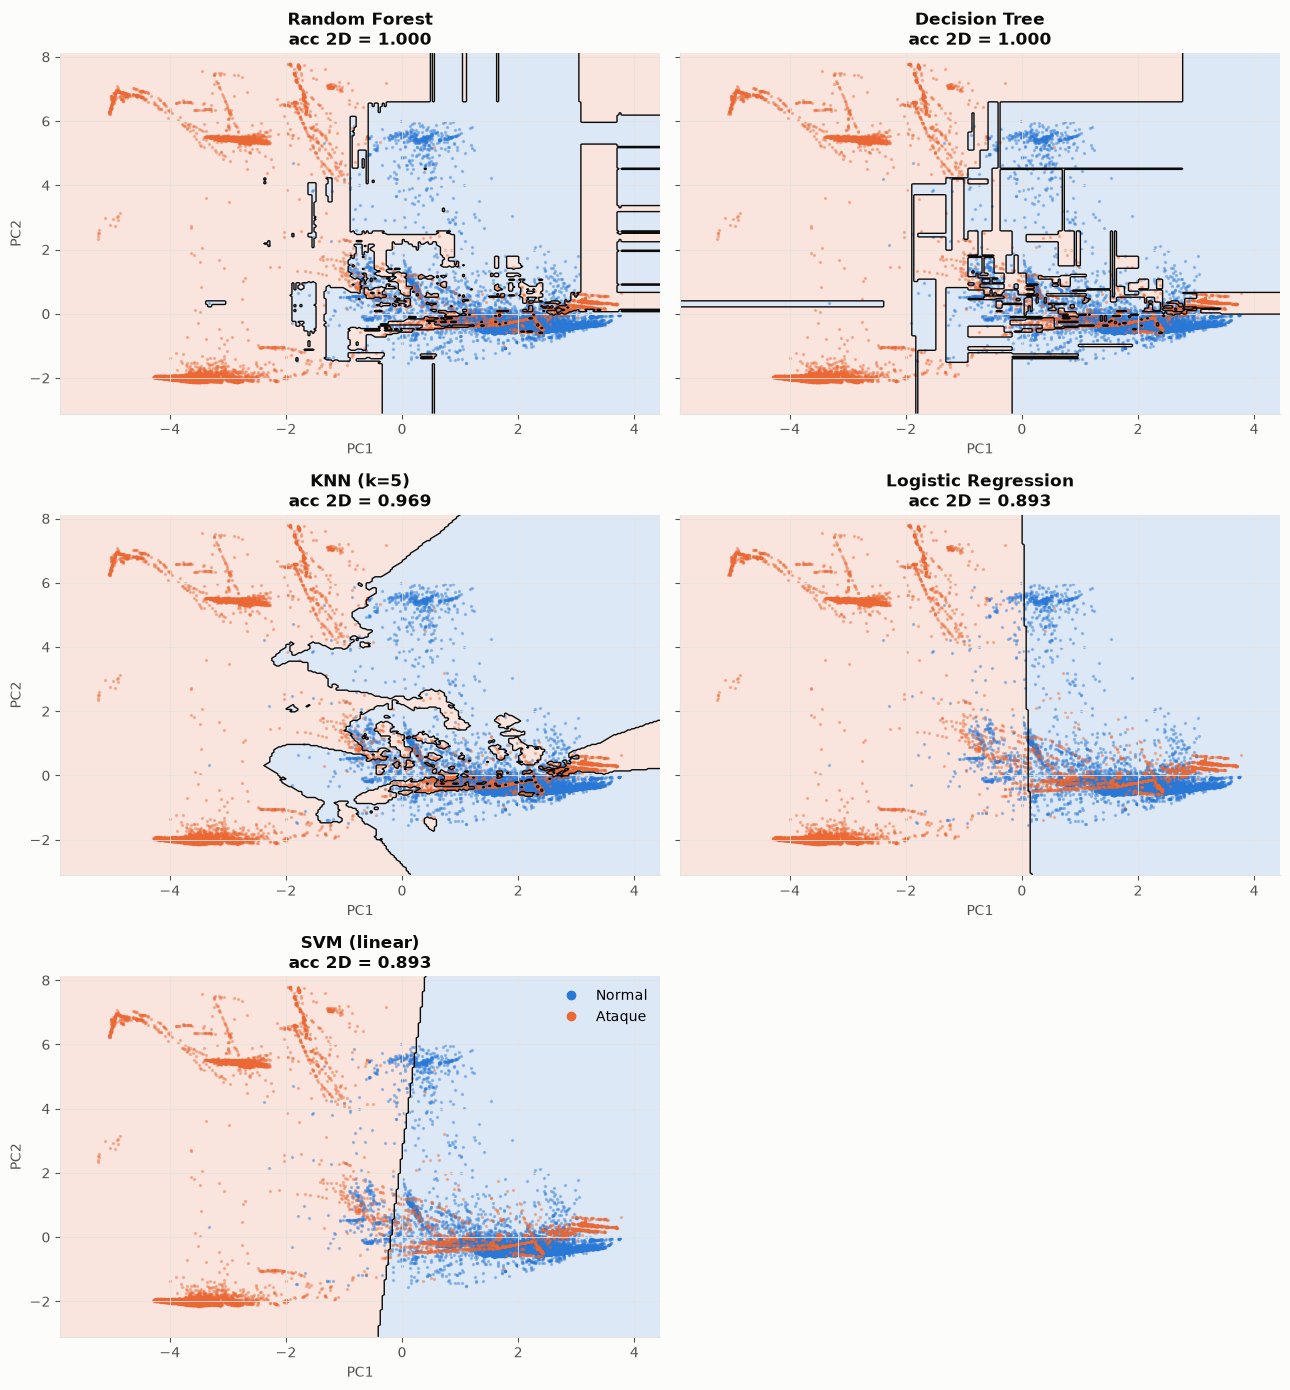

In [37]:
from sklearn.base import clone

Z_tr = pca_kdd.transform(Xtr)[:, :2]
i_b = amostra_estratificada(ytr, 20_000)
Zb, yb = Z_tr[i_b], ytr[i_b]
lo, hi = np.percentile(Zb, [0.5, 99.5], axis=0)
gx, gy = np.meshgrid(
    np.linspace(lo[0] - 1, hi[0] + 1, 300),
    np.linspace(lo[1] - 1, hi[1] + 1, 300),
)
grade = np.c_[gx.ravel(), gy.ravel()]

# Grade 3 linhas x 2 colunas (6 subplots)
fig, axs = plt.subplots(3, 2, figsize=(13, 14), sharey=True)
axs_flat = axs.ravel()

itens_modelos = list(MODELOS.items())

for idx, ax in enumerate(axs_flat):
    if idx >= len(itens_modelos):
        ax.set_visible(False)  # esconde posição sobrando caso MODELOS tenha < 6 itens
        continue

    nome, base = itens_modelos[idx]
    mod = clone(base)
    if nome.startswith("SVM"):
        mod = LinearSVC(C=1.0, random_state=SEED, max_iter=10000)  # mesmo hiperplano, mais rapido

    mod.fit(Zb, yb)
    zz = mod.predict(grade).reshape(gx.shape)

    ax.contourf(gx, gy, zz, levels=[-0.5, 0.5, 1.5], colors=[COR_NORMAL, COR_ATAQUE], alpha=0.15)
    ax.contour(gx, gy, zz, levels=[0.5], colors=[TINTA], linewidths=1)

    for valor, cor in [(0, COR_NORMAL), (1, COR_ATAQUE)]:
        m = yb == valor
        ax.scatter(Zb[m, 0], Zb[m, 1], s=2, alpha=0.35, color=cor)

    ax.set_xlim(gx.min(), gx.max())
    ax.set_ylim(gy.min(), gy.max())
    ax.set_title(f"{nome}\nacc 2D = {accuracy_score(yb, mod.predict(Zb)):.3f}")
    ax.set_xlabel("PC1")

    # Rótulo Y apenas na primeira coluna (linhas 0, 1, 2 -> índices 0, 2, 4)
    if idx % 2 == 0:
        ax.set_ylabel("PC2")

# Legenda no último gráfico preenchido (ou fora da grade, se preferir)
ultimo_ax = axs_flat[min(len(itens_modelos), len(axs_flat)) - 1]
ultimo_ax.legend(
    handles=[
        Line2D([], [], marker="o", ls="", color=COR_NORMAL, label="Normal"),
        Line2D([], [], marker="o", ls="", color=COR_ATAQUE, label="Ataque"),
    ],
    loc="upper right",
)

plt.tight_layout()
salvar(fig, "A6_fronteiras_pca")

## A.7 Comparação entre os modelos

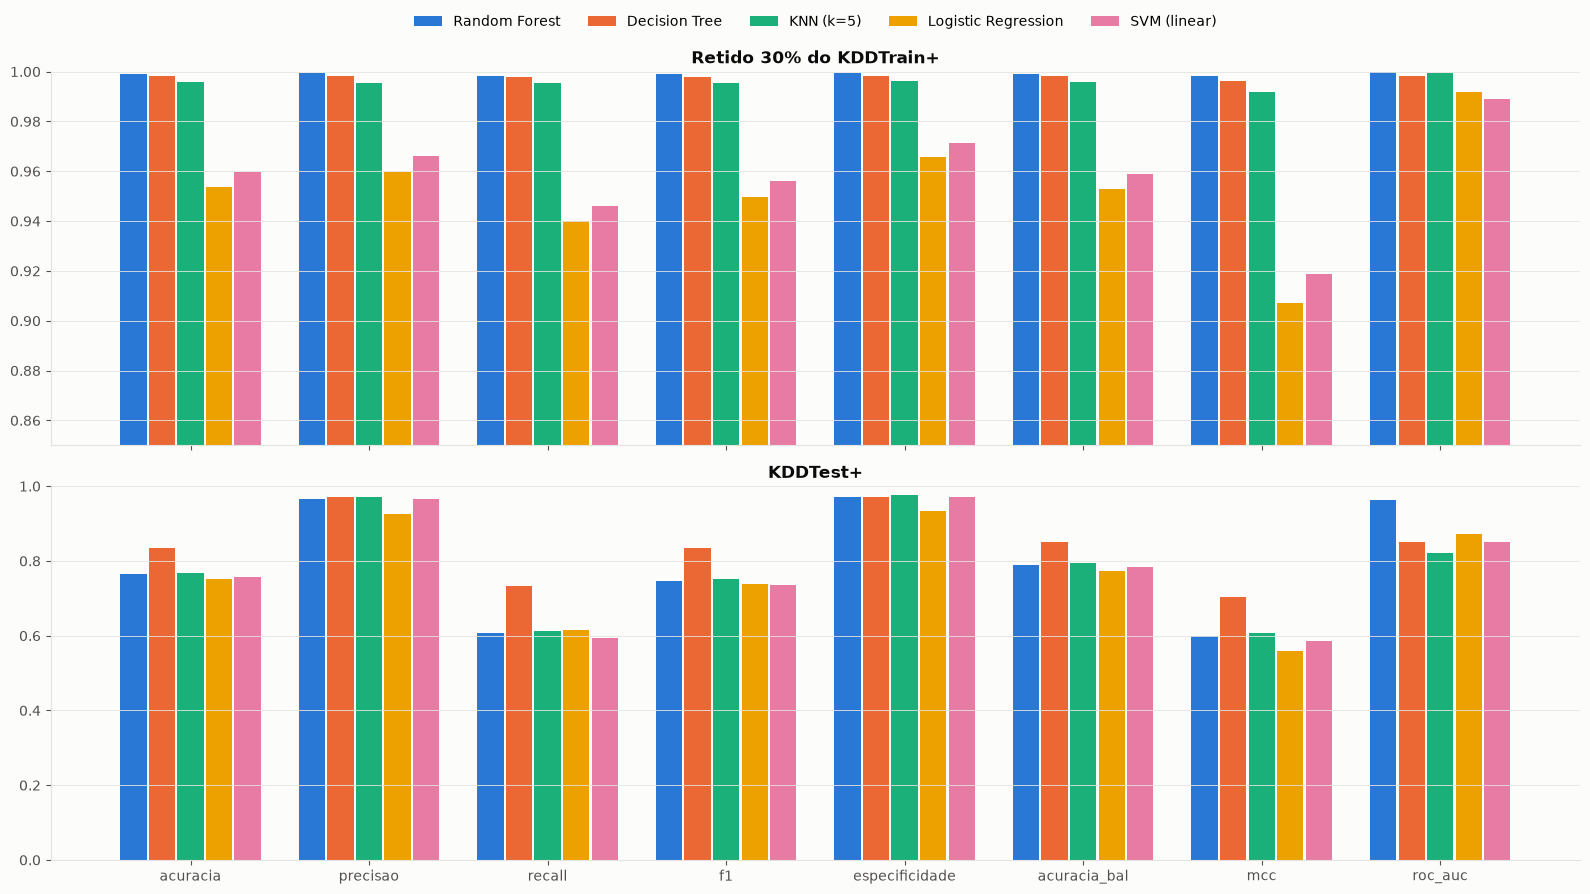

In [28]:
mets = ["acuracia", "precisao", "recall", "f1", "especificidade", "acuracia_bal", "mcc", "roc_auc"]
fig, axs = plt.subplots(2, 1, figsize=(16, 9), sharex=True)
w = 0.8 / len(res)
for ax, (rot, tab) in zip(axs, [("Retido 30% do KDDTrain+", tab_ho), ("KDDTest+", tab_te)]):
    for i, nome in enumerate(res):
        x = np.arange(len(mets)) + (i - (len(res) - 1) / 2) * w
        ax.bar(x, tab.loc[nome, mets], w * 0.92, color=COR_MODELO[nome], label=nome)
    ax.set_title(rot); ax.set_ylim(0.0 if rot == "KDDTest+" else 0.85, 1.0)
    ax.grid(axis="x", visible=False)
axs[1].set_xticks(np.arange(len(mets)), mets)
axs[0].legend(ncol=5, loc="lower center", bbox_to_anchor=(0.5, 1.08))
plt.tight_layout(); salvar(fig, "A7_comparacao_metricas")

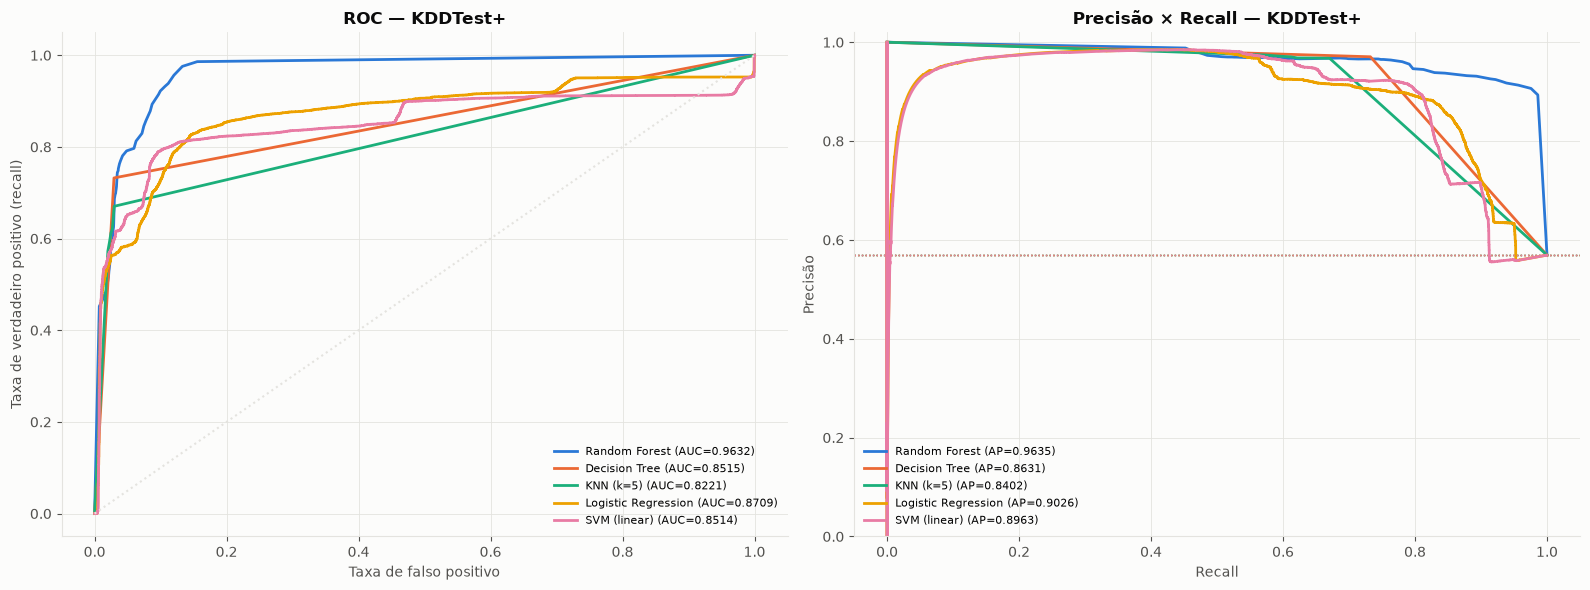

In [29]:
fig, axs = plt.subplots(1, 2, figsize=(16, 6))
curva_roc(axs[0], [(n, y_kdd_teste, r["teste"]["escore"], COR_MODELO[n], "-")
                   for n, r in res.items()], "ROC — KDDTest+")
curva_pr(axs[1], [(n, y_kdd_teste, r["teste"]["escore"], COR_MODELO[n], "-")
                  for n, r in res.items()], "Precisão × Recall — KDDTest+")
plt.tight_layout(); salvar(fig, "A7_roc_pr_todos")

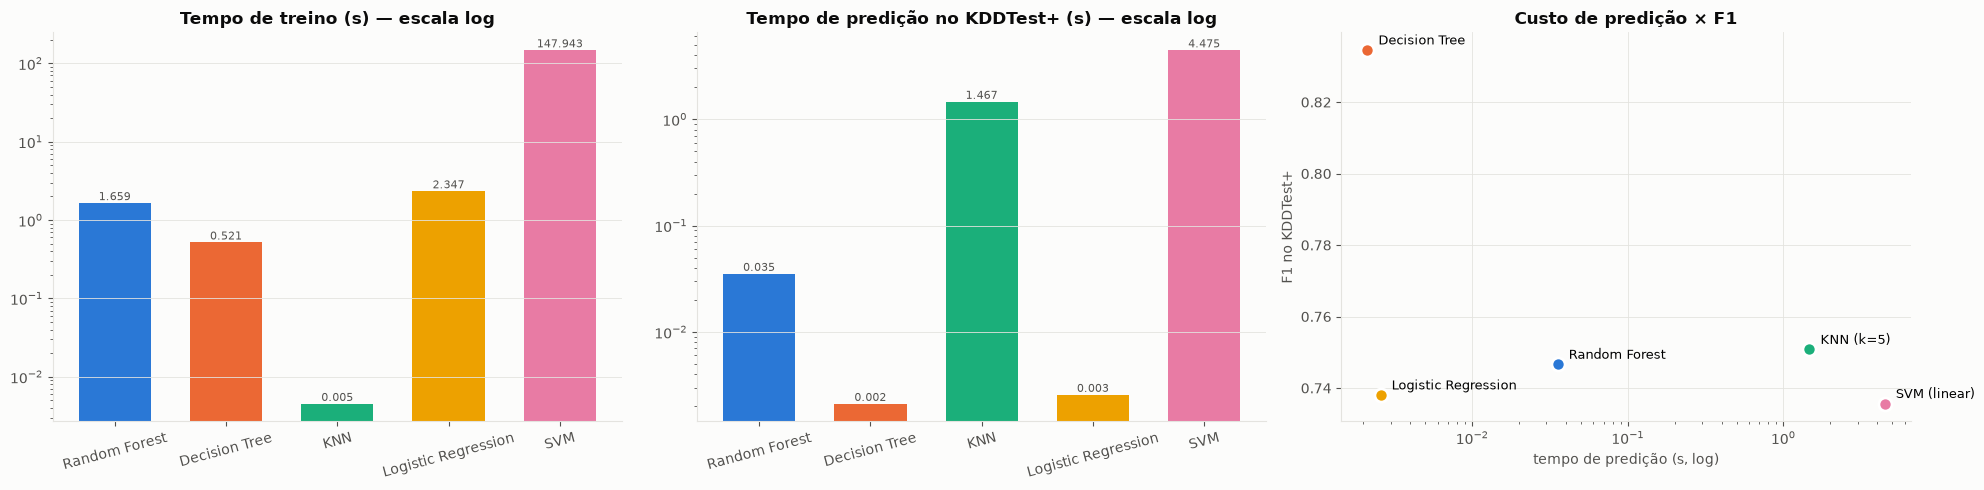

In [30]:
# tempos: dois graficos, nunca dois eixos y
fig, axs = plt.subplots(1, 3, figsize=(20, 5))
nomes = list(res)
for ax, col, tit in [(axs[0], "t_treino_s", "Tempo de treino (s)"),
                     (axs[1], "t_teste_s", "Tempo de predição no KDDTest+ (s)")]:
    v = tab_te.loc[nomes, col]
    ax.bar(range(len(nomes)), v, color=[COR_MODELO[n] for n in nomes], width=0.65)
    for i, t in enumerate(v):
        ax.text(i, t, f"{t:.3f}", ha="center", va="bottom", fontsize=8, color=TINTA_2)
    ax.set_yscale("log"); ax.set_title(tit + " — escala log")
    ax.set_xticks(range(len(nomes)), [n.split(" (")[0] for n in nomes], rotation=15)
    ax.grid(axis="x", visible=False)
# custo × desempenho
for n in nomes:
    axs[2].scatter(tab_te.loc[n, "t_teste_s"], tab_te.loc[n, "f1"], s=90,
                   color=COR_MODELO[n], edgecolor="white", linewidth=2, zorder=3)
    axs[2].annotate(n, (tab_te.loc[n, "t_teste_s"], tab_te.loc[n, "f1"]),
                    textcoords="offset points", xytext=(8, 4), fontsize=9)
axs[2].set_xscale("log"); axs[2].set_xlabel("tempo de predição (s, log)")
axs[2].set_ylabel("F1 no KDDTest+"); axs[2].set_title("Custo de predição × F1")
plt.tight_layout(); salvar(fig, "A7_tempos")

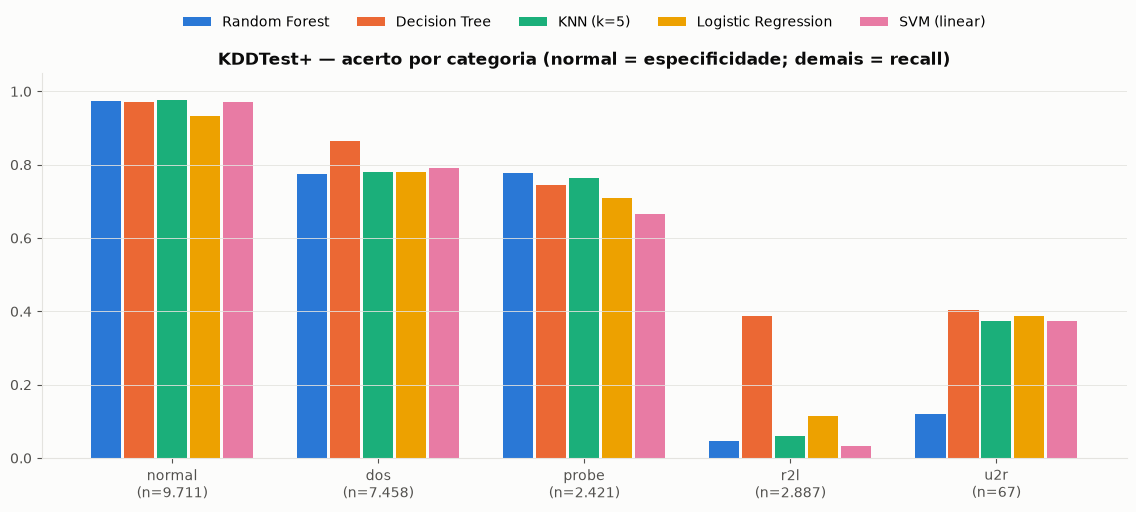

In [31]:
# acerto por categoria, todos os modelos lado a lado (KDDTest+)
fig, ax = plt.subplots(figsize=(14, 5))
w = 0.8 / len(res)
for i, (nome, r) in enumerate(res.items()):
    rg = recall_por_grupo(g_kdd_teste, y_kdd_teste, r["teste"]["pred"])
    ax.bar(np.arange(len(rg)) + (i - (len(res) - 1) / 2) * w, rg, w * 0.92,
           color=COR_MODELO[nome], label=nome)
ax.set_xticks(range(len(ORDEM_GRUPOS)),
              [f"{g}\n(n={(g_kdd_teste == g).sum():,})".replace(",", ".") for g in ORDEM_GRUPOS])
ax.set_ylim(0, 1.05); ax.grid(axis="x", visible=False)
ax.set_title("KDDTest+ — acerto por categoria (normal = especificidade; demais = recall)")
ax.legend(ncol=5, loc="lower center", bbox_to_anchor=(0.5, 1.08))
salvar(fig, "A7_recall_por_categoria")

## A.8 Efeito do PCA e da seleção de atributos

1. Cada modelo treinado nas componentes que somam 95% da variância, comparado
   com os 41 atributos.
2. Decision Tree com os *k* atributos mais importantes (k = 1…41) e com as
   *k* primeiras componentes do PCA.

PCA 95%: 24 componentes


,f1_41,f1_pca,acc_41,acc_pca,t_treino_41,t_treino_pca
modelo,,,,,,
Random Forest,0.7466,0.7387,0.7650,0.7601,1.6587,4.0702
Decision Tree,0.8346,0.7714,0.8348,0.7840,0.5213,3.3041
KNN (k=5),0.7508,0.7450,0.7686,0.7643,0.0045,0.0036
Logistic Regression,0.7380,0.7435,0.7519,0.7556,2.3468,0.3267
SVM (linear),0.7356,0.7225,0.7568,0.7420,147.9429,164.2266


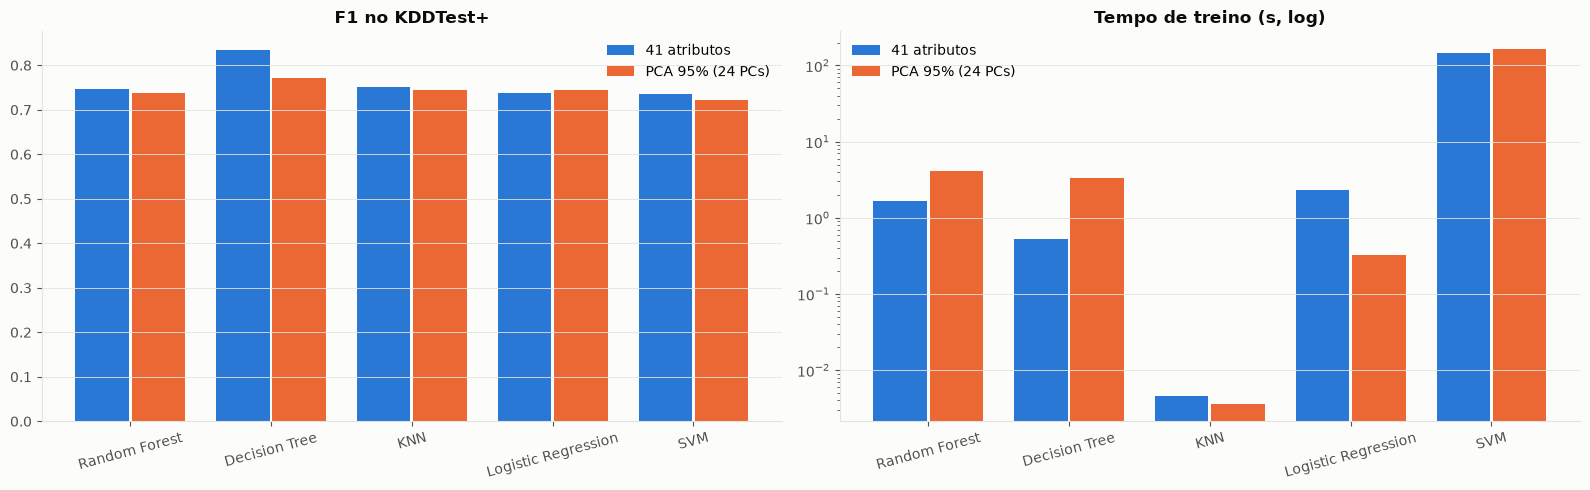

In [32]:
pca95 = PCA(n_components=0.95, random_state=SEED).fit(Xtr)
Ptr, Pho, Pte = pca95.transform(Xtr), pca95.transform(Xho), pca95.transform(Xs_kdd_teste)
print(f"PCA 95%: {pca95.n_components_} componentes")
linhas = []
for nome, base in MODELOS.items():
    from sklearn.base import clone
    mod = clone(base)
    t0 = time.perf_counter(); mod.fit(Ptr, ytr); t_tr = time.perf_counter() - t0
    t0 = time.perf_counter(); pred = mod.predict(Pte); t_te = time.perf_counter() - t0
    m = metricas(y_kdd_teste, pred, escore_de(mod, Pte), t_tr, t_te)
    linhas.append({"modelo": nome, "f1_41": res[nome]["teste"]["m"]["f1"],
                   "f1_pca": m["f1"], "acc_41": res[nome]["teste"]["m"]["acuracia"],
                   "acc_pca": m["acuracia"], "t_treino_41": res[nome]["teste"]["m"]["t_treino_s"],
                   "t_treino_pca": t_tr})
tab_pca = pd.DataFrame(linhas).set_index("modelo")
display(tab_pca)
tab_pca.to_csv(FIG / "A8_pca95_vs_completo.csv")

fig, axs = plt.subplots(1, 2, figsize=(16, 5))
x = np.arange(len(tab_pca))
for ax, a, b, tit in [(axs[0], "f1_41", "f1_pca", "F1 no KDDTest+"),
                      (axs[1], "t_treino_41", "t_treino_pca", "Tempo de treino (s, log)")]:
    ax.bar(x - 0.2, tab_pca[a], 0.38, color=PALETA[0], label="41 atributos")
    ax.bar(x + 0.2, tab_pca[b], 0.38, color=PALETA[1], label=f"PCA 95% ({pca95.n_components_} PCs)")
    ax.set_xticks(x, [n.split(" (")[0] for n in tab_pca.index], rotation=15)
    ax.set_title(tit); ax.legend(); ax.grid(axis="x", visible=False)
axs[1].set_yscale("log")
plt.tight_layout(); salvar(fig, "A8_pca95_vs_completo")

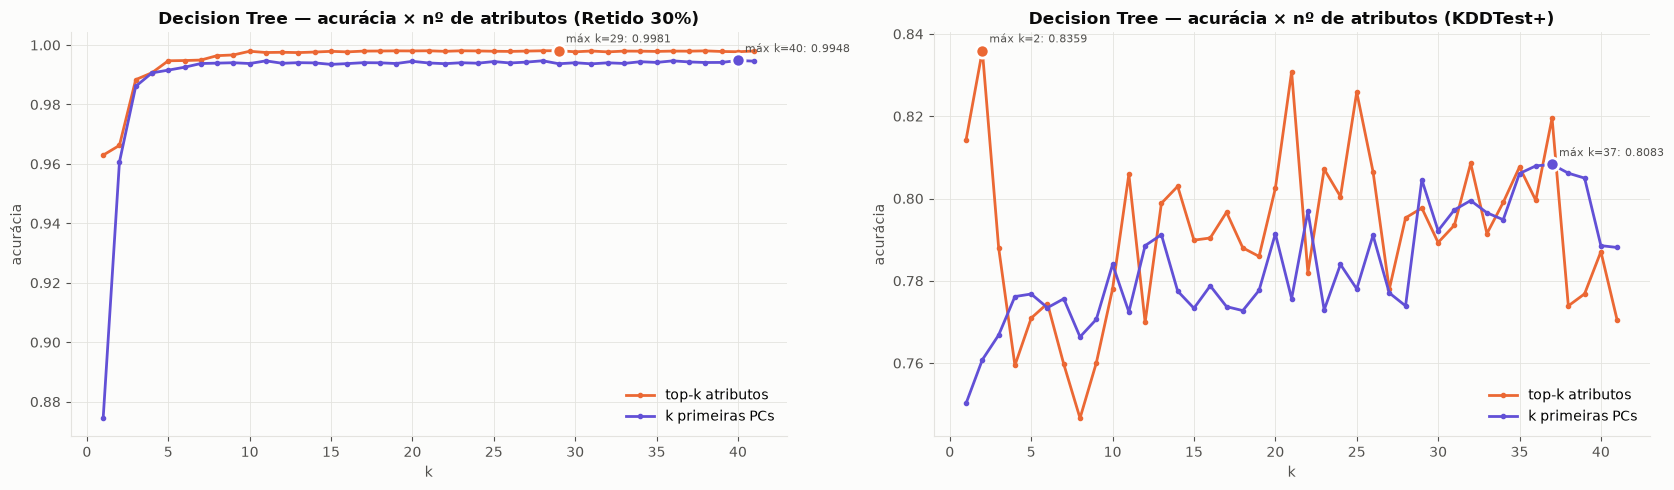

In [33]:
ordem_imp = np.argsort(dt.feature_importances_)[::-1]
pca_tr = PCA(random_state=SEED).fit(Xtr)
P_all_tr, P_all_ho, P_all_te = (pca_tr.transform(a) for a in (Xtr, Xho, Xs_kdd_teste))
ks = np.arange(1, len(FEAT_KDD) + 1)
curvas = {"top-k atributos": ([], []), "k primeiras PCs": ([], [])}
for k in ks:
    cols = ordem_imp[:k]
    d = DecisionTreeClassifier(random_state=SEED).fit(Xtr[:, cols], ytr)
    curvas["top-k atributos"][0].append(accuracy_score(yho, d.predict(Xho[:, cols])))
    curvas["top-k atributos"][1].append(accuracy_score(y_kdd_teste, d.predict(Xs_kdd_teste[:, cols])))
    d = DecisionTreeClassifier(random_state=SEED).fit(P_all_tr[:, :k], ytr)
    curvas["k primeiras PCs"][0].append(accuracy_score(yho, d.predict(P_all_ho[:, :k])))
    curvas["k primeiras PCs"][1].append(accuracy_score(y_kdd_teste, d.predict(P_all_te[:, :k])))

fig, axs = plt.subplots(1, 2, figsize=(17, 5), sharex=True)
for ax, j, tit in [(axs[0], 0, "Retido 30%"), (axs[1], 1, "KDDTest+")]:
    for (rot, v), cor in zip(curvas.items(), [PALETA[1], PALETA[6]]):
        ax.plot(ks, v[j], color=cor, marker="o", markersize=3, label=rot)
        kb = int(np.argmax(v[j])) + 1
        ax.scatter([kb], [max(v[j])], s=90, color=cor, edgecolor="white", linewidth=2, zorder=3)
        ax.annotate(f"máx k={kb}: {max(v[j]):.4f}", (kb, max(v[j])),
                    textcoords="offset points", xytext=(5, 6), fontsize=8, color=TINTA_2)
    ax.set_title(f"Decision Tree — acurácia × nº de atributos ({tit})")
    ax.set_xlabel("k"); ax.set_ylabel("acurácia"); ax.legend(loc="lower right")
plt.tight_layout(); salvar(fig, "A8_dt_num_atributos")

---
# Parte B — Pipeline do IDS: CIC-IDS-2017

Os modelos que estão no sistema, avaliados **offline** (sem banco):

- **Golden set** (`dados/golden/`): fluxos rotulados pelo cronograma oficial
  do CIC-IDS-2017. `ataque-ataque.parquet` = rótulo 1,
  `ataque-benigno.parquet` = controle benigno do mesmo período (rótulo 0) —
  o mesmo critério que `lifecycle.py golden --cicids` grava no banco.
- **Pool do sensor** (`dados/pool/sensor-01/flow/`): tráfego sem rótulo, onde
  o Isolation Forest é treinado. Usado para a distribuição do escore e para a
  fidelidade da árvore substituta.
- **Modelos**: o promovido de cada estágio (`current_flow.joblib`,
  `current_s2_flow.joblib`) e o histórico de candidatos em `dados/models/`.

In [34]:
# A Parte B pode ser rodada sem a Parte A, mas as 4 celulas de configuracao
# do topo (imports/RAIZ, estilo, metricas, pca_360) precisam ter rodado neste
# kernel -- trocar ou reiniciar o kernel apaga tudo o que elas definem.
if "RAIZ" not in globals():
    raise RuntimeError("Rode antes as 4 células de configuração do topo do notebook "
                       "(imports/RAIZ, estilo, métricas, pca_360) e depois a Parte B.")
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from netanomaly import FEATURE_COLS

DADOS = RAIZ / "dados"


def matriz_flow(df):
    return (df[FEATURE_COLS].fillna(0.0).replace([np.inf, -np.inf], 0.0)
            .values.astype(float))


g_atq = pd.read_parquet(DADOS / "golden/ataque-ataque.parquet")
g_ben = pd.read_parquet(DADOS / "golden/ataque-benigno.parquet")
X_gold = np.vstack([matriz_flow(g_atq), matriz_flow(g_ben)])
y_gold = np.r_[np.ones(len(g_atq), int), np.zeros(len(g_ben), int)]

# amostra do pool: ate 200 mil fluxos, proporcional a cada janela
POOL_MAX = 200_000
arqs = sorted((DADOS / "pool/sensor-01/flow").glob("*.parquet"))
pool = pd.concat([pd.read_parquet(a, columns=FEATURE_COLS) for a in arqs], ignore_index=True)
n_pool_total = len(pool)
if len(pool) > POOL_MAX:
    pool = pool.sample(POOL_MAX, random_state=SEED)
X_pool = matriz_flow(pool)

if1 = joblib.load(DADOS / "models/current_flow.joblib")
s2 = joblib.load(DADOS / "models/current_s2_flow.joblib")
assert if1["feature_cols"] == FEATURE_COLS == s2["feature_cols"]
print(f"golden: {n_br(len(y_gold))} fluxos ({n_br(y_gold.sum())} ataque, {n_br((y_gold == 0).sum())} benigno)")
print(f"pool: {n_br(n_pool_total)} fluxos em {len(arqs)} janelas (amostra {n_br(len(X_pool))})")
print(f"IF promovido: contamination={if1['contamination']}  limiar={if1['threshold']:.4f}  "
      f"sklearn {if1['sklearn_version']}")

FileNotFoundError: [Errno 2] No such file or directory: '/home/adelgrin/git/TCC/dados/golden/ataque-ataque.parquet'

## B.1 Estágio 1 — Isolation Forest (modelo promovido)

Escore = `-iso.score_samples(scaler.transform(X))` (maior = mais anômalo);
alerta quando escore ≥ limiar do bundle. O ROC-AUC/AP mostram se o **ranking**
do escore separa ataque de benigno, independente do limiar escolhido.

In [ ]:
def escore_if(bundle, X):
    return -bundle["iso"].score_samples(bundle["scaler"].transform(X))


s_if_gold = escore_if(if1, X_gold)
s_if_pool = escore_if(if1, X_pool)
pred_if = (s_if_gold >= if1["threshold"]).astype(int)
m_if = metricas(y_gold, pred_if, s_if_gold)
display(tabela_metricas([{"modelo": "Isolation Forest (promovido)", **m_if}]))
print(f"alertas no pool: {(s_if_pool >= if1['threshold']).mean():.2%} "
      f"(contamination configurada: {if1['contamination']:.2%})")

In [ ]:
fig, axs = plt.subplots(2, 3, figsize=(20, 10))
matriz_confusao(axs[0, 0], y_gold, pred_if, "Golden — contagem")
matriz_confusao(axs[0, 1], y_gold, pred_if, "Golden — normalizada", True)
curva_roc(axs[0, 2], [("IF promovido", y_gold, s_if_gold, PALETA[0], "-")], "ROC no golden set")
curva_pr(axs[1, 0], [("IF promovido", y_gold, s_if_gold, PALETA[0], "-")], "Precisão × Recall no golden")

bins = np.histogram_bin_edges(np.r_[s_if_gold, s_if_pool], bins=70)
ax = axs[1, 1]
ax.hist(s_if_pool, bins=bins, density=True, color="#9b9a95", alpha=0.5, label="pool (sem rótulo)")
ax.hist(s_if_gold[y_gold == 0], bins=bins, density=True, color=COR_NORMAL, alpha=0.55, label="golden benigno")
ax.hist(s_if_gold[y_gold == 1], bins=bins, density=True, color=COR_ATAQUE, alpha=0.7, label="golden ataque")
ax.axvline(if1["threshold"], color=TINTA, linestyle="--", label=f"limiar {if1['threshold']:.3f}")
ax.set_xlabel("escore de anomalia"); ax.set_ylabel("densidade")
ax.set_title("Distribuição do escore do IF"); ax.legend(fontsize=8)

# percentil do escore de cada fluxo de ataque dentro do pool
pct = np.searchsorted(np.sort(s_if_pool), s_if_gold[y_gold == 1]) / len(s_if_pool)
ax = axs[1, 2]
ax.hist(pct * 100, bins=50, color=COR_ATAQUE)
ax.axvline((1 - if1["contamination"]) * 100, color=TINTA, linestyle="--",
           label=f"limiar = percentil {(1 - if1['contamination']) * 100:.0f}")
ax.set_xlabel("percentil do escore no pool"); ax.set_ylabel("fluxos de ataque")
ax.set_title("Onde os ataques caem na escala do pool"); ax.legend(fontsize=8)
fig.suptitle(f"Isolation Forest (estágio 1) — recall={m_if['recall']:.3f}  "
             f"FPR={m_if['fpr']:.3f}  AUC={m_if['roc_auc']:.3f}", fontsize=14, fontweight="bold")
plt.tight_layout(); salvar(fig, "B1_isolation_forest")

### Recall e FPR de todos os candidatos de IF já treinados

Cada `.joblib` de estágio 1 em `dados/models/` (e os bundles da raiz)
aplicado ao mesmo golden set.

In [ ]:
cands = sorted((DADOS / "models").glob("*_flow*.joblib"))
cands += [RAIZ / "cic2017_flow.joblib", RAIZ / "ataques_flow.joblib", DADOS / "bootstrap_flow.joblib"]
linhas = []
for a in cands:
    if not a.exists():
        continue
    b = joblib.load(a)
    if "iso" not in b or b["feature_cols"] != FEATURE_COLS:
        continue
    s = escore_if(b, X_gold)
    p = (s >= b["threshold"]).astype(int)
    m = metricas(y_gold, p, s)
    linhas.append({"modelo": a.stem, "contamination": b.get("contamination"),
                   "limiar": b["threshold"], "recall": m["recall"], "fpr": m["fpr"],
                   "roc_auc": m["roc_auc"], "ap": m["ap"]})
tab_cand = pd.DataFrame(linhas).set_index("modelo")
display(tab_cand)
tab_cand.to_csv(FIG / "B1_candidatos_if.csv")

fig, axs = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
x = np.arange(len(tab_cand))
for ax, col, cor, tit in [(axs[0], "recall", COR_ATAQUE, "Recall no golden"),
                          (axs[1], "fpr", COR_NORMAL, "Falso positivo no controle benigno"),
                          (axs[2], "roc_auc", PALETA[6], "ROC-AUC do escore")]:
    ax.bar(x, tab_cand[col], color=cor, width=0.7)
    ax.set_title(tit); ax.grid(axis="x", visible=False)
axs[2].axhline(0.5, color=TINTA_2, linestyle=":", linewidth=1)
axs[2].set_xticks(x, tab_cand.index, rotation=70, fontsize=8)
plt.tight_layout(); salvar(fig, "B1_candidatos_if")

## B.2 Árvore substituta (explicabilidade do estágio 1)

A árvore (profundidade 4) aprende o **rótulo do próprio IF**, não o rótulo
real. Fidelidade = quanto ela reproduz as decisões do IF no pool (partição
70/30, como em `netanomaly.metricas_arvore`). É isso que diz se as regras
mostradas no dashboard explicam o detector de verdade.

In [ ]:
arvore = if1["tree"]
rot_if_pool = (s_if_pool >= if1["threshold"]).astype(int)
Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(X_pool, rot_if_pool, test_size=0.30,
                                              random_state=SEED, stratify=rot_if_pool)
arv_ret = DecisionTreeClassifier(max_depth=if1.get("tree_depth", 4), random_state=SEED).fit(Xa_tr, ya_tr)
pred_fid = arv_ret.predict(Xa_te)
m_fid = metricas(ya_te, pred_fid, arv_ret.predict_proba(Xa_te)[:, 1])
print("Fidelidade da árvore ao IF (pool, partição 30%) — 'positivo' = alerta do IF")
display(tabela_metricas([{"modelo": "árvore substituta", **m_fid}]))
pred_arv_gold = arvore.predict(X_gold)
print(f"árvore do bundle aplicada ao golden: recall={recall_score(y_gold, pred_arv_gold):.3f} "
      f"FPR={(pred_arv_gold[y_gold == 0]).mean():.3f}")

fig, axs = plt.subplots(1, 3, figsize=(20, 5.5), gridspec_kw={"width_ratios": [1, 1, 1.4]})
matriz_confusao(axs[0], ya_te, pred_fid, "Árvore × IF — contagem", rotulos=("IF: normal", "IF: alerta"))
matriz_confusao(axs[1], ya_te, pred_fid, "Árvore × IF — normalizada", True, ("IF: normal", "IF: alerta"))
barras_h(axs[2], FEATURE_COLS, arvore.feature_importances_,
         "Importância dos atributos na árvore do bundle", PALETA[2], "importância", n=17)
plt.tight_layout(); salvar(fig, "B2_arvore_fidelidade")

fig, ax = plt.subplots(figsize=(26, 10))
plot_tree(arvore, feature_names=FEATURE_COLS, class_names=["normal", "alerta IF"],
          filled=True, impurity=False, proportion=True, rounded=True, fontsize=8, ax=ax)
ax.set_title("Árvore substituta do IF promovido (profundidade 4, atributos em escala original)")
salvar(fig, "B2_arvore")

## B.3 Estágio 2 — LinearSVC

Mesmo protocolo de `netclassify.py train`: `StandardScaler` + `LinearSVC(C=1,
class_weight="balanced")`, partição estratificada 70/30 do golden set. O modelo
retreinado aqui no 70% é o que é avaliado; o promovido (`current_s2_flow`) foi
treinado no golden **inteiro**, então medi-lo no golden é in-sample e aparece
só como referência.

In [ ]:
Xg_tr, Xg_te, yg_tr, yg_te = train_test_split(X_gold, y_gold, test_size=0.30,
                                              random_state=SEED, stratify=y_gold)
sc2 = StandardScaler().fit(Xg_tr)
t0 = time.perf_counter()
svm2 = LinearSVC(C=1.0, class_weight="balanced", max_iter=10000, random_state=SEED)
svm2.fit(sc2.transform(Xg_tr), yg_tr); t_tr = time.perf_counter() - t0
t0 = time.perf_counter()
marg_te = svm2.decision_function(sc2.transform(Xg_te)); t_te = time.perf_counter() - t0
pred_s2 = (marg_te > 0).astype(int)
m_s2 = metricas(yg_te, pred_s2, marg_te, t_tr, t_te)

marg_prom = s2["svm"].decision_function(s2["scaler"].transform(X_gold))
m_s2_prom = metricas(y_gold, (marg_prom > 0).astype(int), marg_prom)

# IF na MESMA particao de teste, para comparar lado a lado
s_if_te = escore_if(if1, Xg_te)
m_if_te = metricas(yg_te, (s_if_te >= if1["threshold"]).astype(int), s_if_te)
tab_b = tabela_metricas([
    {"modelo": "IF estágio 1 (30% golden)", **m_if_te},
    {"modelo": "LinearSVC estágio 2 (30% golden)", **m_s2},
    {"modelo": "LinearSVC promovido (golden inteiro, in-sample)", **m_s2_prom},
])
display(tab_b); tab_b.to_csv(FIG / "B3_metricas_estagios.csv")

In [ ]:
fig, axs = plt.subplots(2, 3, figsize=(20, 10))
matriz_confusao(axs[0, 0], yg_te, pred_s2, "Teste 30% — contagem")
matriz_confusao(axs[0, 1], yg_te, pred_s2, "Teste 30% — normalizada", True)
curvas = [("LinearSVC (estágio 2)", yg_te, marg_te, PALETA[4], "-"),
          ("Isolation Forest (estágio 1)", yg_te, s_if_te, PALETA[0], "--")]
curva_roc(axs[0, 2], curvas, "ROC — mesma partição de teste")
curva_pr(axs[1, 0], curvas, "Precisão × Recall — mesma partição")
hist_escore(axs[1, 1], yg_te, marg_te, "Margem do hiperplano (teste 30%)", 0.0,
            "decision_function (distância com sinal)")
barras_h(axs[1, 2], FEATURE_COLS, svm2.coef_[0],
         "Pesos do hiperplano (atributos padronizados)\nazul → ataque, laranja → benigno",
         PALETA[4], "peso", n=17)
fig.suptitle(f"LinearSVC (estágio 2) — prec={m_s2['precisao']:.3f}  rec={m_s2['recall']:.3f}  "
             f"F1={m_s2['f1']:.3f}  AUC={m_s2['roc_auc']:.3f}", fontsize=14, fontweight="bold")
plt.tight_layout(); salvar(fig, "B3_linearsvc")

## B.4 PCA do pipeline

1. A projeção 2D congelada no bundle do estágio 2 (`s2["pca"]`), que é a que o
   dashboard usa, com o hiperplano do SVM projetado.
2. Variância explicada dos 17 atributos de fluxo.
3. Giro 360° da projeção 3D do golden set.

In [ ]:
Xs_gold = s2["scaler"].transform(X_gold)
Z2 = s2["pca"].transform(Xs_gold)
pca_g = PCA(random_state=SEED).fit(Xs_gold)
var_g = pca_g.explained_variance_ratio_

fig, axs = plt.subplots(1, 3, figsize=(21, 6))
ax = axs[0]
for valor, nome, cor in [(0, "benigno", COR_NORMAL), (1, "ataque", COR_ATAQUE)]:
    m = y_gold == valor
    ax.scatter(Z2[m, 0], Z2[m, 1], s=4, alpha=0.45, color=cor, label=f"{nome} ({m.sum():,})".replace(",", "."))
lo, hi = np.percentile(Z2, [0.5, 99.5], axis=0)
ax.set_xlim(lo[0] - 1, hi[0] + 1); ax.set_ylim(lo[1] - 1, hi[1] + 1)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title("PCA 2D do bundle do estágio 2 (dashboard)")
leg = ax.legend(markerscale=3)
for h in leg.legend_handles: h.set_alpha(1)

# fronteira do SVM vista no plano: margem media dos pontos de cada celula
from scipy.stats import binned_statistic_2d
est = binned_statistic_2d(Z2[:, 0], Z2[:, 1], marg_prom, "mean", bins=80,
                          range=[[lo[0] - 1, hi[0] + 1], [lo[1] - 1, hi[1] + 1]])
lim = np.nanpercentile(np.abs(est.statistic), 95)
im = axs[1].imshow(est.statistic.T, origin="lower", cmap="RdBu_r", vmin=-lim, vmax=lim,
                   extent=[lo[0] - 1, hi[0] + 1, lo[1] - 1, hi[1] + 1], aspect="auto")
fig.colorbar(im, ax=axs[1], label="margem média do SVM")
axs[1].set_title("Margem do SVM promovido no plano PCA\n(vermelho = lado ataque)")
axs[1].set_xlabel("PC1"); axs[1].grid(False)

k = np.arange(1, len(var_g) + 1)
axs[2].bar(k, var_g, color=PALETA[0], width=0.7, label="por componente")
axs[2].plot(k, np.cumsum(var_g), color=PALETA[1], marker="o", markersize=4, label="acumulada")
axs[2].axhline(0.95, color=TINTA_2, linestyle="--", linewidth=1)
axs[2].set_xticks(k); axs[2].set_xlabel("componente"); axs[2].legend()
axs[2].set_title(f"Variância explicada — 17 atributos de fluxo\n(PC1+PC2 = {var_g[:2].sum():.1%})")
plt.tight_layout(); salvar(fig, "B4_pca_pipeline")

In [ ]:
quadros_gold = pca_360(
    pca_g.transform(Xs_gold)[:, :3], y_gold, [(0, "benigno"), (1, "ataque")],
    FIG / "pca360_golden_cicids", titulo="CIC-IDS-2017 golden · PCA 3D",
    passo=2.5, elev=20, n_max=None, var_exp=var_g)
mostrar_quadros(quadros_gold)

## B.5 SVM do estágio 2 — hiperplano em 2D e 3D

O LinearSVC separa as classes com um hiperplano **w·x + b = 0** em 17
dimensões (atributos padronizados). Para desenhá-lo é preciso escolher uma
projeção, e aqui vão duas:

1. **Base alinhada ao hiperplano (fiel).** Eixo 1 = distância com sinal de
   cada ponto ao hiperplano, `(w·x + b) / ‖w‖`; eixos 2 e 3 = componentes
   principais do que sobra de cada ponto **ortogonal** a w. O hiperplano vira
   exatamente a reta (2D) ou o plano (3D) *eixo 1 = 0*, as margens ficam em
   ±1/‖w‖, e o lado em que cada ponto aparece é o lado em que o SVM o põe.
   Como os benignos se espalham por centenas de margens e os ataques ficam a
   ~1 margem, a visão geral e o 3D usam a distância **em margens com log
   simétrico**, `sign(d)·log(1 + |d|/margem)`: monotônica (ninguém troca de
   lado), hiperplano em 0 e margens em ±log 2. Um segundo painel 2D mostra a
   distância linear com zoom de −5 a +3 margens.
2. **Plano do PCA do dashboard.** A interseção do hiperplano com o subespaço do
   PCA: uma reta no PCA 2D (`s2["pca"]`) e um plano no PCA 3D. Mais familiar,
   mas **aproximada** — um ponto fora do subespaço pode aparecer do lado
   errado. A concordância entre o lado no desenho e o lado real é medida e
   impressa no título.

Pontos com contorno em X (aqua) = classificados errado pelo SVM.

### Modelo do 192.168.60.33

Copie o bundle do servidor (o mais populado, com vereditos) para
`dados/remoto/` e rode esta seção de novo:

```
mkdir -p dados/remoto
scp USUARIO@192.168.60.33:CAMINHO_DO_REPO/dados/models/current_s2_flow.joblib dados/remoto/
```

Sem o arquivo, a seção usa o SVM promovido local.

In [ ]:
S2_ARQ = DADOS / "remoto" / "current_s2_flow.joblib"
if S2_ARQ.exists():
    s2h, ORIGEM_S2 = joblib.load(S2_ARQ), "192.168.60.33"
else:
    s2h, ORIGEM_S2 = s2, "local"
    print(f"[!] {S2_ARQ} não existe -- usando o SVM promovido LOCAL "
          f"(dados/models/current_s2_flow.joblib). Veja o scp acima.")
assert s2h["feature_cols"] == FEATURE_COLS, "bundle com outro conjunto de atributos"
print(f"origem: {ORIGEM_S2}  |  treino: {s2h.get('_treino')}  |  sklearn {s2h['sklearn_version']}")

sc_h, svm_h = s2h["scaler"], s2h["svm"]
Xs_h = sc_h.transform(X_gold)
w, b = svm_h.coef_[0], float(svm_h.intercept_[0])
nw = np.linalg.norm(w)
u = w / nw
dist = Xs_h @ u + b / nw                       # distancia com sinal ao hiperplano
assert np.allclose(dist * nw, svm_h.decision_function(Xs_h))
MARGEM = 1 / nw                                # |f| = 1  <=>  |dist| = 1/||w||

# eixos 2 e 3: PCA do residuo ortogonal a w (nao mexe na distancia)
resid = Xs_h - np.outer(Xs_h @ u, u)
pca_res = PCA(n_components=2, random_state=SEED).fit(resid)
A3 = np.c_[dist, pca_res.transform(resid)]

# Os benignos se espalham por centenas de margens e os ataques ficam a ~1
# margem: em escala linear eles somem colados no hiperplano. Distancia em
# MARGENS com log simetrico -- monotonica, entao ninguem troca de lado:
# hiperplano em 0, margens em ±log(2).
def log_sim(d):
    return np.sign(d) * np.log1p(np.abs(d) / MARGEM)


A3L = np.c_[log_sim(dist), A3[:, 1:]]
LOG2 = np.log(2)

pred_h = (dist > 0).astype(int)
erro_h = pred_h != y_gold
# rotulo para o desenho: 0 benigno, 1 ataque, 2 classificado errado
y_desenho = np.where(erro_h, 2, y_gold)
CLASSES_SVM = [(0, "benigno"), (1, "ataque"), (2, "classificado errado")]
m_h = metricas(y_gold, pred_h, dist)
print(f"||w|| = {nw:.4f}  b = {b:+.4f}  margem = ±{MARGEM:.4f}  |  "
      f"erros: {n_br(erro_h.sum())} de {n_br(len(y_gold))}  |  "
      f"recall={m_h['recall']:.4f}  FPR={m_h['fpr']:.4f}")
if ORIGEM_S2 == "local" or s2h.get("_treino", {}).get("origens", {}).get("golden"):
    print("    (o golden entrou no treino deste SVM: métricas aqui são in-sample)")

In [ ]:
def pontos_svm_2d(ax, P, ys):
    for valor, nome in CLASSES_SVM:
        m = ys == valor
        if not m.any():
            continue
        if valor == 2:
            ax.scatter(P[m, 0], P[m, 1], s=40, marker="X", color=PALETA[2],
                       edgecolor=TINTA, linewidth=0.6, zorder=4,
                       label=f"{nome} ({n_br(m.sum())})")
        else:
            ax.scatter(P[m, 0], P[m, 1], s=5, alpha=0.45,
                       color=COR_NORMAL if valor == 0 else COR_ATAQUE,
                       label=f"{nome} ({n_br(m.sum())})")


def limites(P, q=(0.5, 99.5), extra=()):
    lo, hi = np.percentile(P, q, axis=0)
    lo, hi = np.minimum(lo, min(extra, default=lo[0])), np.maximum(hi, max(extra, default=hi[0]))
    f = (hi - lo) * 0.08
    return lo - f, hi + f


def painel_alinhado(ax, P, margem, xlim, xlabel, titulo):
    ylo, yhi = limites(P[:, 1:2])
    ax.axvspan(xlim[0], 0, color=COR_NORMAL, alpha=0.07)
    ax.axvspan(0, xlim[1], color=COR_ATAQUE, alpha=0.07)
    pontos_svm_2d(ax, P[:, :2], y_desenho)
    ax.axvline(0, color=TINTA, linewidth=2, label="hiperplano (w·x + b = 0)")
    for s in (-1, 1):
        ax.axvline(s * margem, color=TINTA_2, linestyle="--", linewidth=1.2,
                   label="margens (w·x + b = ±1)" if s == 1 else None)
    ax.set_xlim(*xlim); ax.set_ylim(ylo[0], yhi[0])
    ax.set_xlabel(xlabel)
    ax.set_ylabel(f"PC1 do resíduo ⊥ w ({pca_res.explained_variance_ratio_[0]:.1%})")
    ax.set_title(titulo)


fig, axs = plt.subplots(1, 3, figsize=(27, 7.5))

# --- (1) base alinhada, distancia em margens com log simetrico (visao geral)
lo, hi = limites(A3L[:, :1])
painel_alinhado(axs[0], A3L, LOG2, (min(lo[0], -2), max(hi[0], 2)),
                "distância em margens, log simétrico:  sign(d)·log(1 + |d| / margem)",
                "Base alinhada ao hiperplano — visão geral (log)\n← lado benigno  |  lado ataque →")
leg = axs[0].legend(loc="upper left", fontsize=8, markerscale=2)
for h in leg.legend_handles: h.set_alpha(1)

# --- (2) mesma base, distancia linear, zoom de -5 a +3 margens
painel_alinhado(axs[1], A3 / np.r_[MARGEM, 1, 1], 1.0, (-5, 3),
                "distância ao hiperplano em margens  (w·x + b)",
                "Base alinhada — zoom linear perto do hiperplano")

# --- (3) PCA 2D do dashboard: intersecao do hiperplano com o plano PC1×PC2
ax = axs[2]
pca_d = s2h["pca"]
Zd = pca_d.transform(Xs_h)
a2 = pca_d.components_ @ w                      # f restrita ao plano: a·z + c
c2 = float(w @ pca_d.mean_ + b)
lado_desenho = (Zd @ a2 + c2 > 0).astype(int)
conc2 = (lado_desenho == pred_h).mean()
lo, hi = limites(Zd)
gx, gy = np.meshgrid(np.linspace(lo[0], hi[0], 400), np.linspace(lo[1], hi[1], 400))
f = a2[0] * gx + a2[1] * gy + c2
ax.contourf(gx, gy, f, levels=[f.min() - 1, 0, f.max() + 1],
            colors=[COR_NORMAL, COR_ATAQUE], alpha=0.07)
pontos_svm_2d(ax, Zd, y_desenho)
cs = ax.contour(gx, gy, f, levels=[-1, 0, 1], colors=[TINTA_2, TINTA, TINTA_2],
                linestyles=["--", "-", "--"], linewidths=[1.2, 2, 1.2])
ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1])
ax.set_xlabel(f"PC1 ({pca_d.explained_variance_ratio_[0]:.1%})")
ax.set_ylabel(f"PC2 ({pca_d.explained_variance_ratio_[1]:.1%})")
ax.set_title("Interseção do hiperplano com o PCA 2D do dashboard\n"
             f"lado no desenho = lado real em {conc2:.1%} dos pontos")
fig.suptitle(f"LinearSVC estágio 2 ({ORIGEM_S2}) — hiperplano em 2D", fontsize=14, fontweight="bold")
plt.tight_layout(); salvar(fig, f"B5_svm_hiperplano_2d_{ORIGEM_S2.replace('.', '_')}")

In [ ]:
def desenhar_plano(ax, a, c, niveis=((0, 0.22), (-1, 0.06), (1, 0.06)), n=25):
    # plano a·z + c = nivel dentro da caixa atual do eixo 3D
    lims = [ax.get_xlim(), ax.get_ylim(), ax.get_zlim()]
    k = int(np.argmax(np.abs(a)))               # resolve na coordenada mais inclinada
    o = [i for i in range(3) if i != k]
    g1, g2 = np.meshgrid(np.linspace(*lims[o[0]], n), np.linspace(*lims[o[1]], n))
    for nivel, alfa in niveis:
        gk = (nivel - c - a[o[0]] * g1 - a[o[1]] * g2) / a[k]
        gk = np.where((gk >= lims[k][0]) & (gk <= lims[k][1]), gk, np.nan)
        P = [None] * 3
        P[o[0]], P[o[1]], P[k] = g1, g2, gk
        ax.plot_surface(*P, color=TINTA if nivel == 0 else TINTA_2, alpha=alfa,
                        linewidth=0, shade=False)
    ax.set_xlim(lims[0]); ax.set_ylim(lims[1]); ax.set_zlim(lims[2])


# PCA 3D do golden (mesma escala do SVM) e a intersecao do hiperplano com ele
pca3_h = PCA(n_components=3, random_state=SEED).fit(Xs_h)
Z3h = pca3_h.transform(Xs_h)
a3 = pca3_h.components_ @ w
c3 = float(w @ pca3_h.mean_ + b)
conc3 = ((Z3h @ a3 + c3 > 0).astype(int) == pred_h).mean()

# base alinhada em log simetrico: hiperplano em x = 0 e margens em x = ±log 2,
# entao a = (1/log 2, 0, 0) faz os niveis 0 e ±1 do desenhar_plano caírem nelas
A_ALIN, C_ALIN = np.array([1 / LOG2, 0.0, 0.0]), 0.0
EIXOS_ALIN = ["distância em margens (log simétrico)",
              f"PC1 resíduo ⊥ w ({pca_res.explained_variance_ratio_[0]:.1%})",
              f"PC2 resíduo ⊥ w ({pca_res.explained_variance_ratio_[1]:.1%})"]
EIXOS_PCA = [f"PC{k+1} ({v:.1%})" for k, v in enumerate(pca3_h.explained_variance_ratio_)]

fig = plt.figure(figsize=(20, 8.5))
for i, (P, a, c, eixos, tit) in enumerate([
        (A3L, A_ALIN, C_ALIN, EIXOS_ALIN, "Base alinhada ao hiperplano (exata, eixo 1 em log)"),
        (Z3h, a3, c3, EIXOS_PCA, f"PCA 3D — lado no desenho = lado real em {conc3:.1%}")]):
    ax = fig.add_subplot(1, 2, i + 1, projection="3d")
    for valor, nome in CLASSES_SVM:
        m = y_desenho == valor
        if valor == 2:
            ax.scatter(*P[m].T, s=30, marker="X", color=PALETA[2], edgecolor=TINTA,
                       linewidth=0.5, depthshade=False, label=f"{nome} ({n_br(m.sum())})")
        else:
            ax.scatter(*P[m].T, s=4, alpha=0.45, depthshade=False,
                       color=COR_NORMAL if valor == 0 else COR_ATAQUE,
                       label=f"{nome} ({n_br(m.sum())})")
    lo, hi = limites(P)
    if i == 0:
        lo[0], hi[0] = min(lo[0], -2), max(hi[0], 2)
    ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1]); ax.set_zlim(lo[2], hi[2])
    desenhar_plano(ax, a, c)
    ax.set_xlabel(eixos[0]); ax.set_ylabel(eixos[1]); ax.set_zlabel(eixos[2])
    ax.view_init(elev=20, azim=-60)
    ax.set_title(tit + "\nplano escuro = hiperplano; claros = margens ±1")
    leg = ax.legend(loc="upper left", fontsize=8, markerscale=2)
    for h in leg.legend_handles: h.set_alpha(1)
fig.suptitle(f"LinearSVC estágio 2 ({ORIGEM_S2}) — hiperplano em 3D", fontsize=14, fontweight="bold")
plt.tight_layout(); salvar(fig, f"B5_svm_hiperplano_3d_{ORIGEM_S2.replace('.', '_')}")

### Hiperplano 3D — giro de 360° (passo de 2,5°)

In [ ]:
sufixo = ORIGEM_S2.replace(".", "_")
quadros_svm_alin = pca_360(
    A3L, y_desenho, CLASSES_SVM, FIG / f"svm360_alinhado_{sufixo}",
    titulo="SVM · base alinhada ao hiperplano", n_max=None, eixos=EIXOS_ALIN,
    extra=lambda ax: desenhar_plano(ax, A_ALIN, C_ALIN))
mostrar_quadros(quadros_svm_alin)

quadros_svm_pca = pca_360(
    Z3h, y_desenho, CLASSES_SVM, FIG / f"svm360_pca_{sufixo}",
    titulo="SVM · hiperplano no PCA 3D", n_max=None, eixos=EIXOS_PCA,
    extra=lambda ax: desenhar_plano(ax, a3, c3))
mostrar_quadros(quadros_svm_pca)

---
## Arquivos gerados

Lista tudo o que foi salvo em `notebooks/figuras/`.

In [ ]:
for p in sorted(FIG.iterdir()):
    if p.is_dir():
        n = len(list(p.glob("frame_*.png")))
        gif = p / "giro_360.gif"
        extra = f" + giro_360.gif ({gif.stat().st_size / 1e6:.1f} MB)" if gif.exists() else ""
        print(f"{p.name}/  {n} quadros{extra}")
    else:
        print(p.name)